# Sewage Project

As common in sewer systems, the Brussels sewer system has the capacity to flow out into the Senne whenever the sewage collector is at capacity. This happens at multiple locations in Brussels and can cause harm to biodiversity and nature, since untreated sewage is released into natural water bodies. As overflow events can depend on rainfall, this project aims to answer the research question: **How can future water level in the sewer best be modeled using sewage and rainfall data?**

One such station is at the Lion overflow location, for which the sewer data of 3 years is provided. For the same time, we have rainfall data from two sensors: Avant-Port, geographically close to the Lion overflow station, and Flagey.

To answer our question, we will compare and evaluate three different models for predicting waterlevel at t+60: Artificial Neural Network, Linear Regression and Random Forest Regressor. Subsequently, the best model will also be trained to predict waterlevel at t+15. Finally, the predictions will be used to classify whether the sewer will overflow or not.

In [303]:
import numpy as np
import pandas as pd

import random


import wandb
import os
import pprint

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from feature_engine.timeseries.forecasting import LagFeatures, WindowFeatures

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import confusion_matrix, classification_report

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, cross_val_score, TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from scipy.stats import randint


random_state = 138
random.seed(random_state)

In [304]:
Pluv_2022_path = 'Pluviometer data/2022.xlsx'
Pluv_2023_path = 'Pluviometer data/2023.xlsx'
Pluv_2024_path = 'Pluviometer data/2024.xlsx'

U24_2022_path = 'Sewage data/U24_2022.csv'
U24_2023_path = 'Sewage data/U24_2023.csv'
U24_2024_path = 'Sewage data/U24_2024.csv'

In [305]:
pd_2022_df = pd.read_excel(Pluv_2022_path)
pd_2023_df = pd.read_excel(Pluv_2023_path)
pd_2024_df = pd.read_excel(Pluv_2024_path)

In [306]:
sd_2022_df = pd.read_csv(U24_2022_path)
sd_2023_df = pd.read_csv(U24_2023_path)
sd_2024_df = pd.read_csv(U24_2024_path)

# Data Inspection

Firstly, we will do an initial inspection of the data of both datasets. This serves to understand its structure, quality and potential issues before going into the data exploration.

## Rainfall data from Flagey and Avant Port

In [307]:
pd_2022_df.head()

,FLOWBRU - PLUVIO ALL,U24,C12,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,date/time (SER UTC+1.00),Pluv. Avant-Port[mm],Pluvio Flagey[mm],NaN,NaN,NaN,NaN,NaN,NaN
1,2022-01-01 00:00:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-01-01 00:05:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-01-01 00:10:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2022-01-01 00:15:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [308]:
pd_2023_df.head()

,FLOWBRU - PLUVIO ALL,P01,P14
0,date/time (SER UTC+1.00),Pluv. Avant-Port[mm],Pluvio Flagey[mm]
1,2023-01-01 00:00:00,0,0
2,2023-01-01 00:05:00,0,0
3,2023-01-01 00:10:00,0,0
4,2023-01-01 00:15:00,0,0


In [309]:
pd_2024_df.head()

,FLOWBRU - PLUVIO ALL,P01,P14
0,date/time (SER UTC+1/00),Pluv. Avant-Port[mm],Pluvio Flagey[mm]
1,2024-01-01 00:00:00,0,0
2,2024-01-01 00:05:00,0,0
3,2024-01-01 00:10:00,0,0
4,2024-01-01 00:15:00,0,0


The first inspection of the head of the datasets shows us that we have 3 meaningful columns: datetime, the sensor at Avant-Port and at Flagey. We also see some additional columns in the dataset of the year 2022 without any data in it. This suggests that they can be removed later. Column names do not seem to have any duplicates, which is good. The first row in all datasets is a sort of extra header, which will also have to be removed for model training.

Moreover, we get a first glance at the data: the rainfall data has two sensors, one at Avant-Port, one at Flagey, both measured in mm and in 5-minute intervals.

In [310]:
pd_2022_df.tail()

,FLOWBRU - PLUVIO ALL,U24,C12,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
105116,2022-12-31 23:35:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
105117,2022-12-31 23:40:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
105118,2022-12-31 23:45:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
105119,2022-12-31 23:50:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
105120,2022-12-31 23:55:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [311]:
pd_2023_df.tail()

,FLOWBRU - PLUVIO ALL,P01,P14
105116,2023-12-31 23:35:00,0,0
105117,2023-12-31 23:40:00,0,0
105118,2023-12-31 23:45:00,0,0
105119,2023-12-31 23:50:00,0,0
105120,2023-12-31 23:55:00,0,0


In [312]:
pd_2024_df.tail(13)

,FLOWBRU - PLUVIO ALL,P01,P14
105409,TOTAL,1035.1,1010.2
105410,JAN,79.4,90.0
105411,FEB,101.0,108.6
105412,MAA,67.1,61.5
105413,APR,70.6,59.2
105414,MEI,120.8,102.8
105415,JUN,62.5,67.9
105416,JUL,106.5,100.3
105417,AUG,102.6,101.7
105418,SEP,101.2,99.3


Looking at the tail of the rainfall dataset, we see nothing special in the years 2022 and 2023. However, in 2024, there are some monthly totals in the tail. While these can be useful later to check seasonality, they will have to be removed from the dataset for later modelling. We will store the monthly totals as well in another set in order to be able to check them later.

In [313]:
print("Length of the datasets")
print(f"2022: {len(pd_2022_df)}")
print(f"2023: {len(pd_2023_df)}")
print(f"2024: {len(pd_2024_df)}")

Length of the datasets
2022: 105121
2023: 105121
2024: 105422


In [314]:
print("Null values: ")
print(f"2022: {pd_2022_df.isna().sum()}")
print(f"2023: {pd_2023_df.isna().sum()}")
print(f"2024: {pd_2024_df.isna().sum()}")

Null values: 
2022: FLOWBRU - PLUVIO ALL         0
U24                          0
C12                          0
Unnamed: 3              105121
Unnamed: 4              105121
Unnamed: 5              105121
Unnamed: 6              105121
Unnamed: 7              105121
Unnamed: 8              105120
dtype: int64
2023: FLOWBRU - PLUVIO ALL    0
P01                     0
P14                     0
dtype: int64
2024: FLOWBRU - PLUVIO ALL    0
P01                     0
P14                     0
dtype: int64


Except for the columns that will be removed anyway, we have no missing values in any of the rainfall datasets. That means we won't have to interpolate or remove any.

In [315]:
print("Duplicated rows: ")
print(f"2022: {pd_2022_df.duplicated().sum()}")
print(f"2023: {pd_2023_df.duplicated().sum()}")
print(f"2024: {pd_2024_df.duplicated().sum()}")

Duplicated rows: 
2022: 0
2023: 0
2024: 0


Good news, no duplicated rows either.

In [316]:
print("Duplicated values in columns: ")
duplicated_cols = pd_2022_df.T.duplicated()
print(pd_2022_df.columns[duplicated_cols])

Duplicated values in columns: 
Index(['Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7'], dtype='str')


Neither do we have duplicated columns, as stated already above. Here we see that we also have no duplicated values in the columns. We see the unnamed columns in the set, but they will be removed anyway.

## Sewage data

In [317]:
sd_2022_df.head()

,Date,Value
0,2022-01-01 00:00:33,883.908
1,2022-01-01 00:01:34,881.589
2,2022-01-01 00:02:33,874.169
3,2022-01-01 00:03:33,876.719
4,2022-01-01 00:04:33,876.719


In [318]:
sd_2023_df.head()

,Date,Value
0,2023-01-01 00:00:22,900.834
1,2023-01-01 00:01:22,905.704
2,2023-01-01 00:02:22,905.704
3,2023-01-01 00:03:22,905.704
4,2023-01-01 00:04:22,900.834


In [319]:
sd_2024_df.head()

,Date,Value
0,2024-01-01 00:00:33,1271.772
1,2024-01-01 00:01:33,1281.511
2,2024-01-01 00:02:33,1288.699
3,2024-01-01 00:03:33,1303.307
4,2024-01-01 00:04:33,1317.684


The datasets of sewage for the three years all look the same. We have two columns (Date and Value) and the data is sampled each minute. Note that this is a different interval from the rainfall data and will later have to be adjusted in order to merge the two datasets. The value is waterlevel in cm.

In [320]:
sd_2022_df.tail()

,Date,Value
524142,2022-12-30 23:55:22,1417.684
524143,2022-12-30 23:56:22,1415.365
524144,2022-12-30 23:57:22,1417.684
524145,2022-12-30 23:58:22,1417.684
524146,2022-12-30 23:59:22,1417.684


In [321]:
sd_2023_df.tail()

,Date,Value
524149,2023-12-30 23:55:33,1083.490
524150,2023-12-30 23:56:33,1080.939
524151,2023-12-30 23:57:33,1080.939
524152,2023-12-30 23:58:33,1088.359
524153,2023-12-30 23:59:33,1090.678


In [322]:
sd_2024_df.tail()

,Date,Value
525594,2024-12-30 23:55:33,1129.401
525595,2024-12-30 23:56:33,1121.981
525596,2024-12-30 23:57:33,1119.663
525597,2024-12-30 23:58:33,1117.344
525598,2024-12-30 23:59:33,1117.344


There are no abnormalities in the tails either. You can see that it ends with the last minute of the last day of the year as expected.

In [323]:
print("Null values: ")
print(f"2022: {sd_2022_df.isna().sum()}")
print(f"2023: {sd_2023_df.isna().sum()}")
print(f"2024: {sd_2024_df.isna().sum()}")

Null values: 
2022: Date     0
Value    0
dtype: int64
2023: Date     0
Value    0
dtype: int64
2024: Date     0
Value    0
dtype: int64


We have no missing values in the 'unclean' dataset, so we don't have to interpolate or remove any.

In [324]:
print("Duplicates: ")
print(f"2022: {sd_2022_df.duplicated().sum()}")
print(f"2023: {sd_2023_df.duplicated().sum()}")
print(f"2024: {sd_2024_df.duplicated().sum()}")

Duplicates: 
2022: 0
2023: 0
2024: 0


Good news, no duplicated rows either.

In [325]:
sd_2022_df.describe()

,Value
count,524147.000000
mean,1060.490601
std,474.574762
min,-927.500000
25%,862.111000
50%,1014.453000
75%,1074.741000
max,3738.984000


In [326]:
sd_2023_df.describe()

,Value
count,524154.000000
mean,1127.806313
std,522.863346
min,-1027.500000
25%,863.673000
50%,981.929000
75%,1117.344000
max,3636.434000


In [327]:
sd_2024_df.describe()

,Value
count,525599.000000
mean,1280.347823
std,549.805414
min,648.724000
25%,989.117000
50%,1119.663000
75%,1300.757000
max,3638.984000


Looking at the quick summary statistics for the 3 year sewage data, we see similar values in the three years.

One thing that jumps out quite clearly is that in both year 2022 and 2023, there are negative values in the dataset. Since negative waterlevels are physically impossible, these can be considered erroneous and be removed (or interpolated) later.

# Data Cleaning

## Rainfall data from Flagey and Avant Port

Firstly, we will remove  the first row that acts as a second header and is not needed for our machine learning models.

In [328]:
pd_2022_df = pd_2022_df.iloc[1:]
pd_2022_df.head()

,FLOWBRU - PLUVIO ALL,U24,C12,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
1,2022-01-01 00:00:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-01-01 00:05:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-01-01 00:10:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2022-01-01 00:15:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5,2022-01-01 00:20:00,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [329]:
pd_2023_df = pd_2023_df.iloc[1:]
pd_2023_df.head()

,FLOWBRU - PLUVIO ALL,P01,P14
1,2023-01-01 00:00:00,0,0
2,2023-01-01 00:05:00,0,0
3,2023-01-01 00:10:00,0,0
4,2023-01-01 00:15:00,0,0
5,2023-01-01 00:20:00,0,0


In [330]:
pd_2024_df = pd_2024_df.iloc[1:]
pd_2024_df.head()

,FLOWBRU - PLUVIO ALL,P01,P14
1,2024-01-01 00:00:00,0,0
2,2024-01-01 00:05:00,0,0
3,2024-01-01 00:10:00,0,0
4,2024-01-01 00:15:00,0,0
5,2024-01-01 00:20:00,0,0


Next, we remove the unnamed columns of '22 as well as rename the columns U24 and C12 to P01 and P14, to match the column names of the other years.

In [331]:
pd_2022_df.drop(['Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8'], axis=1, inplace=True)
pd_2022_df = pd_2022_df.rename(columns={'U24': 'P01', 'C12': 'P14'})

In [332]:
rainfall_complete = pd.concat([pd_2022_df, pd_2023_df, pd_2024_df], ignore_index=True)
rainfall_complete.columns.values

<StringArray>
['FLOWBRU - PLUVIO ALL', 'P01', 'P14']
Length: 3, dtype: str

For simplicity, the columns will get more descriptive names.

In [333]:
rainfall_complete = rainfall_complete.rename(columns={"FLOWBRU - PLUVIO ALL":"datetime", "P01":"avant_port_mm", "P14":"flagey_mm"})

Because our analysis needs only the original timestamp-based observations, the monthly summary rows should be removed. However, we will store them for later seasonality checks.

In [334]:
monthly_total_24 = rainfall_complete.tail(13)
rainfall_complete = rainfall_complete.iloc[:-13]

In order to later merge the rainfall dataset with the sewage dataset, the datetime columns should be datetime objects instead of strings. Similarly, the type of the rainfall values should be numeric, not strings.
Using *errors='coerce'* makes invalid values turn into NaN, so you can easily find and remove them later.

In [335]:
rainfall_complete['datetime'] = pd.to_datetime(rainfall_complete['datetime'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
rainfall_complete['avant_port_mm'] = pd.to_numeric(rainfall_complete['avant_port_mm'], errors='coerce')
rainfall_complete['flagey_mm'] = pd.to_numeric(rainfall_complete['flagey_mm'], errors='coerce')

print(rainfall_complete.isna().sum())

datetime         0
avant_port_mm    0
flagey_mm        0
dtype: int64


In [336]:
rainfall_complete = rainfall_complete.sort_values("datetime").reset_index(drop=True)
rainfall_complete = rainfall_complete.set_index('datetime')
rainfall_complete.head()

,avant_port_mm,flagey_mm
datetime,,
2022-01-01 00:00:00,0.0,0.0
2022-01-01 00:05:00,0.0,0.0
2022-01-01 00:10:00,0.0,0.0
2022-01-01 00:15:00,0.0,0.0
2022-01-01 00:20:00,0.0,0.0


## Sewage data

The sewage data will be cleaned similarly. We might expect more unclean data, as the project pdf pointed out that the sewage data is not pre-cleaned.

In [337]:
sewage_complete = pd.concat([sd_2022_df, sd_2023_df, sd_2024_df], ignore_index=True)
sewage_complete.columns.values

<StringArray>
['Date', 'Value']
Length: 2, dtype: str

We will name the columns similarly to fit the rainfall dataset and prepare the datetime column in the same way.

In [338]:
sewage_complete = sewage_complete.rename(columns={"Date":"datetime", "Value":"waterlevel"})

In [339]:
sewage_complete['datetime'] = pd.to_datetime(sewage_complete['datetime'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

**IMPORTANT**: the timestamp correction is explained further down in the EDA part.

In [340]:
sewage_complete = sewage_complete.sort_values("datetime").reset_index(drop=True)
sewage_complete_old_timestamp = sewage_complete.copy()
sewage_complete_old_timestamp = sewage_complete_old_timestamp.set_index('datetime')

# NOTE: this part will be explained later
# NOTE: comment the following line to disable timestamp correction (sewage timestamp + 1 hour)
sewage_complete['datetime'] = sewage_complete['datetime'] + pd.Timedelta(hours=1)
sewage_complete = sewage_complete.set_index('datetime')


In [341]:
sewage_complete.head()

,waterlevel
datetime,
2022-01-01 01:00:33,883.908
2022-01-01 01:01:34,881.589
2022-01-01 01:02:33,874.169
2022-01-01 01:03:33,876.719
2022-01-01 01:04:33,876.719


As noted previously, there are negative values in the waterlevel, which are unrealistic. We have to take care of these. Let's first check how many we have and the distribution of negative values.

In [342]:
neg_df = sewage_complete[sewage_complete['waterlevel'] < 0]

print("amount of negative values: ", len(neg_df))

amount of negative values:  6872


In [343]:
neg_df['dateOnly'] = pd.to_datetime(neg_df.index).date
print(neg_df.groupby('dateOnly').size())


dateOnly
2022-06-04     694
2022-06-05    1440
2022-06-06    1440
2022-06-07    1439
2022-06-08    1440
2022-06-09     416
2023-12-19       3
dtype: int64


In 2022, we have a 5 day gap of negative values, 04-06-2022 to 05-06-2022. Since the gap is multiple days, it indicates a fault with the sensor. This data is unusable and should NOT be trained on. However, we will set the negative values to NaN for now, in order not to mess with the historical context and remove (or flag) them later after creating our input features (especially lagged water level).

For 2023, since there are only 3 negative values. These can potentially be interpolated. Let's check these further in the context of the day they occur.


In [344]:
print(neg_df[neg_df.index.date == pd.Timestamp('2023-12-19').date()])

                     waterlevel    dateOnly
datetime                                   
2023-12-19 12:50:22    -1027.50  2023-12-19
2023-12-19 12:51:22    -1027.50  2023-12-19
2023-12-19 12:52:33     -203.88  2023-12-19


In [345]:
print(sewage_complete[(sewage_complete.index > pd.to_datetime('2023-12-19 11:45'))
    & (sewage_complete.index < pd.to_datetime('2023-12-19 12:00'))])

                     waterlevel
datetime                       
2023-12-19 11:45:33    1102.736
2023-12-19 11:46:33    1105.054
2023-12-19 11:47:33    1105.054
2023-12-19 11:48:33    1107.605
2023-12-19 11:49:33    1114.793
2023-12-19 11:50:33    1117.344
2023-12-19 11:51:33    1112.474
2023-12-19 11:52:33    1121.981
2023-12-19 11:53:33    1119.663
2023-12-19 11:54:33    1124.532
2023-12-19 11:55:33    1117.344
2023-12-19 11:56:33    1124.532
2023-12-19 11:57:33    1129.401
2023-12-19 11:58:33    1129.401
2023-12-19 11:59:33    1129.401


In [346]:
sewage_complete.isna().any()

waterlevel    False
dtype: bool

Above you can see that the three negative waterlevel values are situated in subsequent timesteps (11:50-11:52). Before this, the waterlevel was 1208.934 and after, it amounted to 1216.354. Given that there is not a big change between them and also before and after the changes to waterlevel are minimal, we can use linear interpolation for these.

Note: GenAI was used for help with the interpolation (ChatGPT).


In [347]:
# create a mask for the day and negative values
negative_2023_mask = ((sewage_complete.index.date == pd.Timestamp('2023-12-19').date())
    & (sewage_complete['waterlevel'] < 0))

# set to NaN
sewage_complete.loc[negative_2023_mask, 'waterlevel'] = np.nan

# check how many NaNs (should be 3)
print("NaNs before interpolation: ", sewage_complete['waterlevel'].isna().sum())

# interpolate
sewage_complete['waterlevel'] = sewage_complete['waterlevel'].interpolate(method='linear')

# check how many NaNs after (should be 0)
print("NaNs after interpolation: ", sewage_complete['waterlevel'].isna().sum())


NaNs before interpolation:  3
NaNs after interpolation:  0


In [348]:
print(sewage_complete[(sewage_complete.index > pd.to_datetime('2023-12-19 11:45'))
    & (sewage_complete.index < pd.to_datetime('2023-12-19 12:00'))])

                     waterlevel
datetime                       
2023-12-19 11:45:33    1102.736
2023-12-19 11:46:33    1105.054
2023-12-19 11:47:33    1105.054
2023-12-19 11:48:33    1107.605
2023-12-19 11:49:33    1114.793
2023-12-19 11:50:33    1117.344
2023-12-19 11:51:33    1112.474
2023-12-19 11:52:33    1121.981
2023-12-19 11:53:33    1119.663
2023-12-19 11:54:33    1124.532
2023-12-19 11:55:33    1117.344
2023-12-19 11:56:33    1124.532
2023-12-19 11:57:33    1129.401
2023-12-19 11:58:33    1129.401
2023-12-19 11:59:33    1129.401


As we can see above, the negative values are interpolated and the timeseries looks reasonable now.



**Clean up faulty 5 day period**
Now that the missing values of 2023 are interpolated, we can set the faulty negative waterlevels of 2024 to NaN, so they can be removed later.

In [349]:
sewage_complete.loc[sewage_complete['waterlevel'] < 0, 'waterlevel'] = np.nan
sewage_complete.isna().sum()

waterlevel    6869
dtype: int64

In [350]:
# do the same for the timestamp incorrect data, will be used later to make a point about timestamp correction.

sewage_complete_old_timestamp.loc[sewage_complete_old_timestamp['waterlevel'] < 0, 'waterlevel'] = np.nan
sewage_complete_old_timestamp.isna().sum()

waterlevel    6872
dtype: int64

# Preprocessing & Merging

## Downsampling

The rainfall data is recorded at 5-minute intervals. Before merging with the rainfall data (1-minute resolution), we aggregate sewage to 5-minute windows. For this aggregation we will the maximum aggregation, since we are trying to predict waterlevels and detect overflow events, meaning high spikes in waterlevels. Keeping the maximum level of the 5 min interval prevents us from losing momentary spikes in waterlevel.

In [351]:
sewage_5min = sewage_complete.resample('5min').max()
sewage_5min.head()

# downsample also old timestamp data
sewage_5min_old_timestamp = sewage_complete_old_timestamp.resample('5min').max()


In [352]:
sewage_5min.describe()

,waterlevel
count,313411.000000
mean,1170.966932
std,509.432173
min,463.750000
25%,902.164000
50%,1040.887000
75%,1178.621000
max,3738.984000


## Merging Datasets


In [353]:
rainfall_complete.head()

,avant_port_mm,flagey_mm
datetime,,
2022-01-01 00:00:00,0.0,0.0
2022-01-01 00:05:00,0.0,0.0
2022-01-01 00:10:00,0.0,0.0
2022-01-01 00:15:00,0.0,0.0
2022-01-01 00:20:00,0.0,0.0


In [354]:
sewage_5min.head()

,waterlevel
datetime,
2022-01-01 01:00:00,883.908
2022-01-01 01:05:00,881.589
2022-01-01 01:10:00,881.589
2022-01-01 01:15:00,871.850
2022-01-01 01:20:00,876.719


From the heads, we can see that there is a 1 hour gap, which is expected, since the timestamp of the sewage data was shifted. We merge with "inner" so that only the rows that exist in both DFs will be kept. 

In [355]:
sewage_rainfall_df_old_timestamp = rainfall_complete.join(sewage_5min_old_timestamp, how='inner')
sewage_rainfall_df = rainfall_complete.join(sewage_5min, how='inner')

In [356]:
print(len(sewage_5min.index))
print(len(rainfall_complete.index))
print(len(sewage_rainfall_df.index))

315360
315648
315360


In [357]:
sewage_rainfall_df.head()

,avant_port_mm,flagey_mm,waterlevel
datetime,,,
2022-01-01 01:00:00,0.0,0.0,883.908
2022-01-01 01:05:00,0.0,0.0,881.589
2022-01-01 01:10:00,0.0,0.0,881.589
2022-01-01 01:15:00,0.0,0.0,871.850
2022-01-01 01:20:00,0.0,0.0,876.719


In [358]:
sewage_rainfall_df.isna().sum()

avant_port_mm       0
flagey_mm           0
waterlevel       1949
dtype: int64

In [359]:
sewage_rainfall_df.describe()

,avant_port_mm,flagey_mm,waterlevel
count,315360.000000,315360.000000,313411.000000
mean,0.008427,0.008454,1170.966932
std,0.076177,0.073524,509.432173
min,0.000000,0.000000,463.750000
25%,0.000000,0.000000,902.164000
50%,0.000000,0.000000,1040.887000
75%,0.000000,0.000000,1178.621000
max,12.700000,10.000000,3738.984000


## Labelling

We will have two datasets, one for the 15 min prediciton model, the other for the 60 min prediction model.

In [360]:
sewage_rainfall_15min_df = sewage_rainfall_df.copy()
sewage_rainfall_15min_old_timestamp_df = sewage_rainfall_df_old_timestamp.copy()


**60 minute prediction data**

Here we set add a column containing the target variable (the data that needs to be predicted). We start with the model predicting t+60. That means we need to shift 12 rows in order to get the value at t+60 (60/5=12).

_Note_: since we are using shift here, we had to make sure that until now, no indices had been removed, since a shift of 12 has to be equal to one hour in order to do the labelling well. From here on, we will use LagFeatures and WindowFeatures to create timelag features based on timestamps, not shifted rows. Sometimes shift is still used, but in combination with a check that the timesteps are valid.

In [361]:
sewage_rainfall_df['target'] = sewage_rainfall_df['waterlevel'].shift(-12)
sewage_rainfall_df_old_timestamp['target'] = sewage_rainfall_df_old_timestamp['waterlevel'].shift(-12)


In [362]:
print(sewage_rainfall_df['target'].head())
print(sewage_rainfall_df['waterlevel'].head())

datetime
2022-01-01 01:00:00    862.111
2022-01-01 01:05:00    857.242
2022-01-01 01:10:00    857.242
2022-01-01 01:15:00    859.792
2022-01-01 01:20:00    854.923
Name: target, dtype: float64
datetime
2022-01-01 01:00:00    883.908
2022-01-01 01:05:00    881.589
2022-01-01 01:10:00    881.589
2022-01-01 01:15:00    871.850
2022-01-01 01:20:00    876.719
Name: waterlevel, dtype: float64


We remove the rows for which we cannot have a target.

In [363]:
print(sewage_rainfall_df.isna().sum()['target'])
sewage_rainfall_df = sewage_rainfall_df.dropna()
print(sewage_rainfall_df.isna().sum()['target'])

1961
0


In [364]:
# do the same for the timestamp non corrected data
print(sewage_rainfall_df_old_timestamp.isna().sum()['target'])
sewage_rainfall_df_old_timestamp = sewage_rainfall_df_old_timestamp.dropna()
print(sewage_rainfall_df_old_timestamp.isna().sum()['target'])

1961
0


**15 min prediction data**
We will do the same for the 15 min prediction model. 

In [365]:
sewage_rainfall_15min_df['target'] = sewage_rainfall_15min_df['waterlevel'].shift(-3)
sewage_rainfall_15min_old_timestamp_df['target'] = sewage_rainfall_15min_old_timestamp_df['waterlevel'].shift(-3)

In [366]:
print("NaNs before: ")
print(sewage_rainfall_15min_df.isna().sum()['target'])
print(sewage_rainfall_15min_old_timestamp_df.isna().sum()['target'])

sewage_rainfall_15min_df = sewage_rainfall_15min_df.dropna()
sewage_rainfall_15min_old_timestamp_df = sewage_rainfall_15min_old_timestamp_df.dropna()

print("\nNaNs after:")
print(sewage_rainfall_15min_df.isna().sum()['target'])
print(sewage_rainfall_15min_old_timestamp_df.isna().sum()['target'])


NaNs before: 
1952
1952

NaNs after:
0
0


# Exploratory Data Analaysis

## First statistics of rainfall

Let's first have a look at how our rainfall data looks for the two sensors in Avant-Port and Flagey.

In [367]:
print("__________________________________________________________\n| Summary statistics of rainfall |\n__________________________________________________________")
print(sewage_rainfall_df[['avant_port_mm', 'flagey_mm']].describe())

__________________________________________________________
| Summary statistics of rainfall |
__________________________________________________________
       avant_port_mm      flagey_mm
count  313363.000000  313363.000000
mean        0.008423       0.008345
std         0.076212       0.072759
min         0.000000       0.000000
25%         0.000000       0.000000
50%         0.000000       0.000000
75%         0.000000       0.000000
max        12.700000      10.000000


This first glance at the data gives a first idea of the data. Both rain columns have very similar values, which makes sense since the sensors are not far apart geographically speaking. The mean for both sensors is very small (about 0.0084mm), which might be very surprising for the average Brussels' inhabitant, but makes sense in the context of 5m resolution rainfall data over 3 years. The maximum of rainfall in mm in Avant Port is slightly higher (2.7mm more) than in Flagey.




In [368]:
for col in ['avant_port_mm', 'flagey_mm']:
    zero_ratio = (sewage_rainfall_df[col] == 0.0).mean()
    print(f"{col}: {zero_ratio:.2%} zeros")

avant_port_mm: 95.89% zeros
flagey_mm: 95.91% zeros


The very small mean as well as the small standard deviation also suggests that this is a dataset with a long tail. And indeed, both sensors have more than 95% of the data 0.


In [369]:
# YE for year end
annual_rainfall_avant_port = sewage_rainfall_df['avant_port_mm'].resample('YE').sum()
annual_rainfall_flagey = sewage_rainfall_df['flagey_mm'].resample('YE').sum()

annual_rainfall = pd.concat([annual_rainfall_avant_port, annual_rainfall_flagey], axis=1)
annual_rainfall.columns = ['avant_port_total', 'flagey_total']

annual_rainfall

,avant_port_total,flagey_total
datetime,,
2022-12-31,617.8,606.9
2023-12-31,988.7,998.7
2024-12-31,1033.0,1009.5


Looking at the annual rainfall, this data fits very well in the context of Belgium rainfall data between 2006 and 2016, where annual totals were ranging from 737mm to 977mm (Statista, 2025). It should be noted that 2022 and 2024 seem to be years out of the ordinary, with 2022 having less than average rain and 2024 being a rain intensive year. This should be kept in mind for the split of data into training, validation and test sets: given the chronological split, the data will be trained on the earlier part of the dataset and could have an impact on model performance.

### Outliers in rainfall?

Based on standard meteorological classifications, rainfall below 0.2 mm/5 min is considered light, 0.2–0.6 mm/5 min moderate, 0.6–4 mm/5 min heavy, and above 4 mm/5 min violent (Barani Design, 2020). Let's have a look at the violent rainfall events and their context to determine if there are any outliers.

In [370]:
def boxplot_rainfall(dataset, flagey_col_name='flagey_mm', avant_port_col_name='avant_port_mm'):
    fig, axes = plt.subplots(1, 2, figsize=(12,6))

    sns.boxplot(dataset[flagey_col_name], ax=axes[0])
    axes[0].set_title('Flagey Rainfall')

    sns.boxplot(dataset[avant_port_col_name], ax=axes[1])
    axes[1].set_title('Avant Port Rainfall')

    plt.show()

def scatterplot_rainfall(dataset, title, flagey_col_name='flagey_mm', avant_port_col_name='avant_port_mm'):
    fig, ax = plt.subplots(figsize=(13, 6))
    sns.scatterplot(x=dataset.index, y=dataset[flagey_col_name],
                    ax=ax, label='Flagey', color='steelblue')
    sns.scatterplot(x=dataset.index, y=dataset[avant_port_col_name],
                    ax=ax, label='Avant Port', color='coral')
    ax.set_title(title)
    ax.set_xlabel('Date')
    ax.set_ylabel('mm / 5 min')
    ax.set_xticks(dataset.index)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    ax.tick_params(axis='x', rotation=90)
    ax.legend()
    plt.tight_layout()
    plt.show()


def lineplot_rainfall(dataset, title, flagey_col_name='flagey_mm', avant_port_col_name='avant_port_mm'):

    fig, ax = plt.subplots(figsize=(13, 6))

    ax.plot(dataset.index, dataset[flagey_col_name], "steelblue", linewidth=0.8, label="Flagey")
    ax.plot(dataset.index, dataset[avant_port_col_name], "crimson", linewidth=0.8, label="Avant Port")

    ax.set_ylabel("Rainfall (mm/5min)")
    ax.set_title(title)
    ax.set_xlabel('Time')
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.tick_params(axis='x', rotation=90)
    ax.legend()
    plt.tight_layout()
    ax.grid(True, alpha=0.3)

    plt.show()

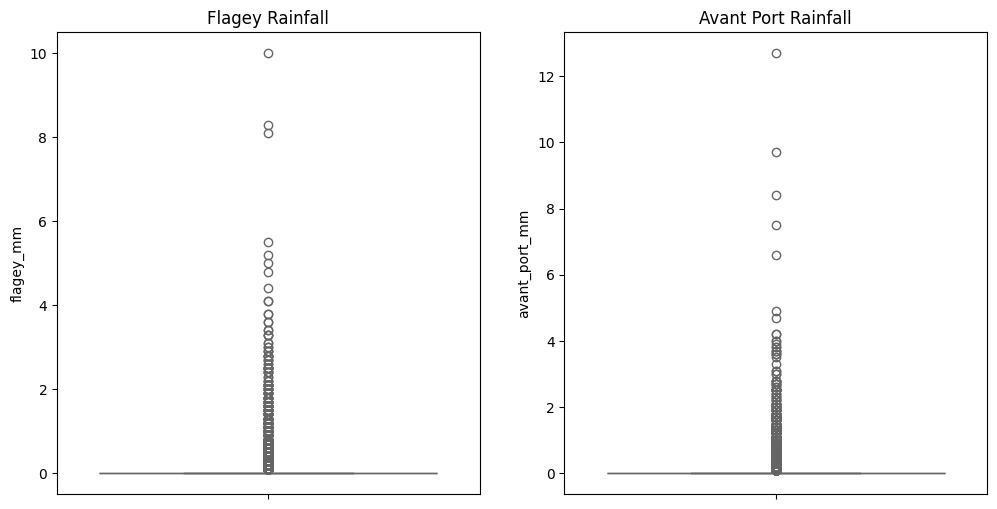

In [371]:
boxplot_rainfall(sewage_rainfall_df)

From this plot, we can see that both datasets include only a few events that exceed the 4mm of rainfall per 5 mins needed for "violent" rainfall events. Let's check some of the data at really high values of rainfall.


Amount of violent rainfall event in 3 years: 18


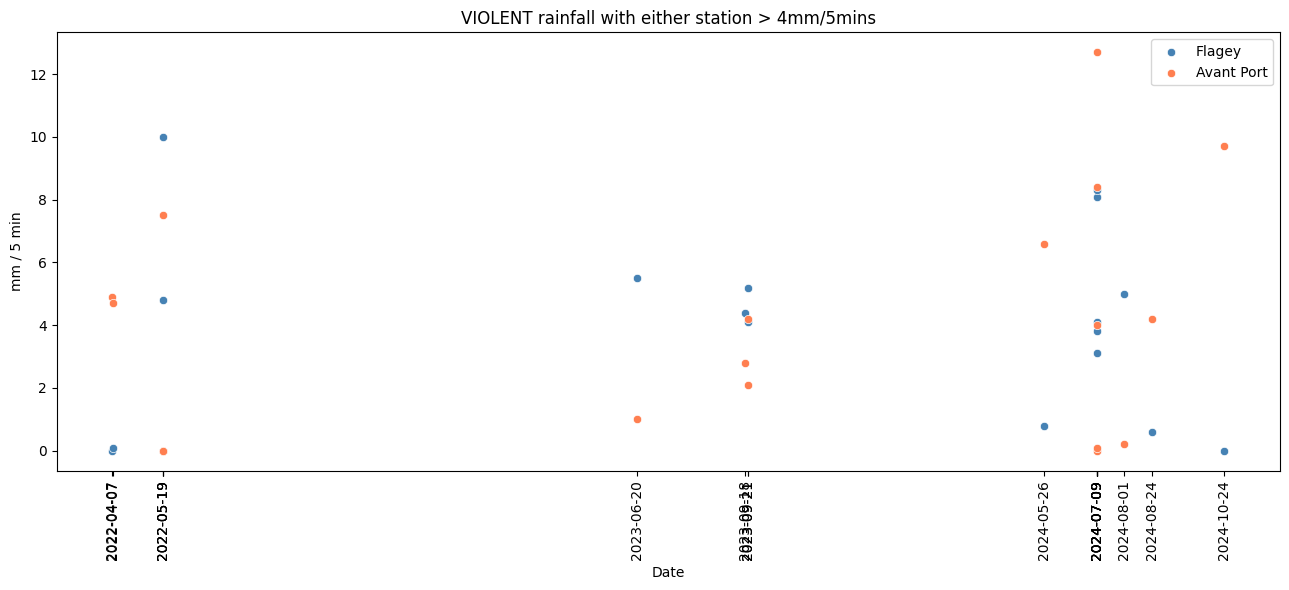

                     avant_port_mm  flagey_mm  waterlevel    target
datetime                                                           
2022-04-07 08:40:00            4.9        0.0    1183.490  1975.575
2022-04-07 09:25:00            4.7        0.1    1809.089  2292.084
2022-05-19 11:50:00            7.5        0.0    1656.747  3717.188
2022-05-19 12:45:00            0.0       10.0    3717.188  3552.789
2022-05-19 12:50:00            0.0        4.8    3717.188  3538.413
2023-06-20 18:35:00            1.0        5.5    1182.501  3614.638
2023-09-18 16:45:00            2.8        4.4    2576.070  2407.032
2023-09-21 15:20:00            2.1        4.1    3597.710  3571.277
2023-09-21 15:25:00            4.2        5.2    3436.094  3547.162
2024-05-26 14:55:00            6.6        0.8    1564.167  2544.766
2024-07-09 15:15:00            0.0        8.1    1117.344  3610.000
2024-07-09 15:20:00            4.0        8.3    1230.731  3614.638
2024-07-09 15:25:00            8.4        3.8   

In [372]:
violent_upper_limit = 4
violent_rainfall = sewage_rainfall_df[(sewage_rainfall_df['flagey_mm'] > violent_upper_limit) | (sewage_rainfall_df['avant_port_mm'] > violent_upper_limit)]
print(f"\nAmount of violent rainfall event in 3 years: {len(violent_rainfall)}")

scatterplot_rainfall(violent_rainfall, "VIOLENT rainfall with either station > 4mm/5mins")
print(violent_rainfall)


From this scatterplot, we can see the few high intensity rainfall events in the dataset (>4mm / 5mins in either of the stations). It is interesting to see that the high intensity rainfall events mostly occur in 2024, which makes sense considering that we already identified 2024 to be the year of the highest rainfall out of the three years recorded. Given the meteorological context of rain classification mentioned before, this dataset contains 18 datapoints that fall into the violent rain category, consistent with rare but realistic convective storm events. Even though the high rainfall events occur sometimes at merely one of the stations, this is consistent with rainfall being a highly localized phenomenon.

Let's spot check the event on the 9th July 2024, where rainfall reaches up to 12mm/5 mins in Avant Port. To determine whether such events are realistic, we must look at the context in which they occurred.

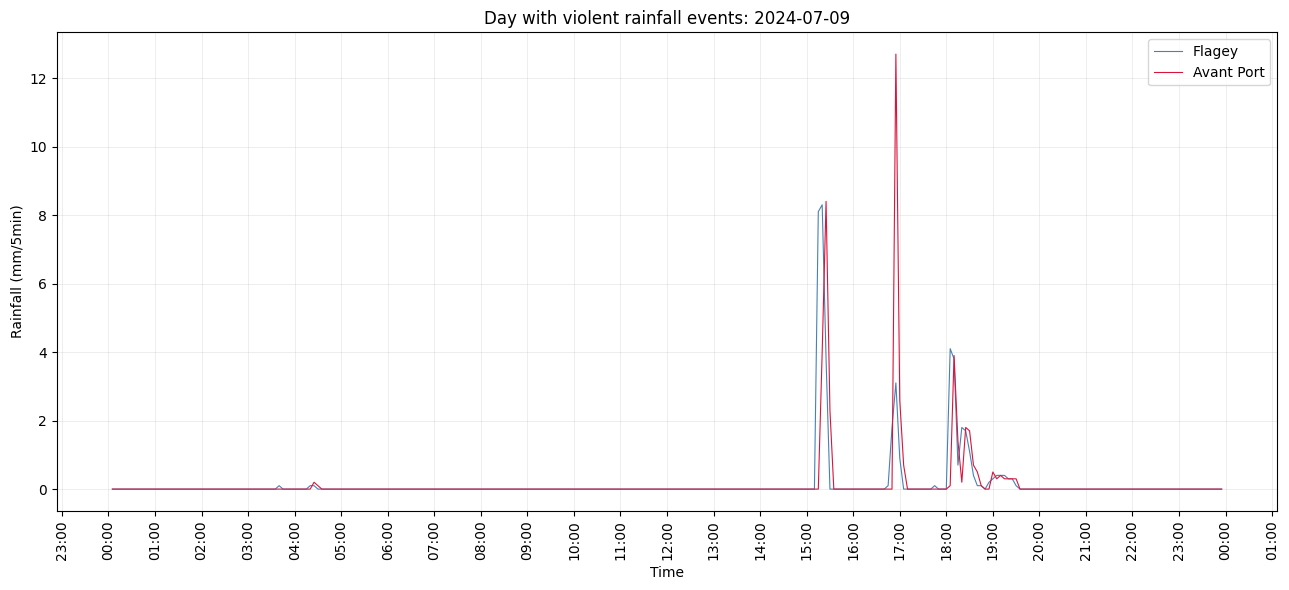

In [373]:
day_2024_07_09 = sewage_rainfall_df[(sewage_rainfall_df.index > pd.to_datetime('2024-07-09 0:00')) & (sewage_rainfall_df.index < pd.to_datetime('2024-07-10 0:00')) ]

lineplot_rainfall(day_2024_07_09, "Day with violent rainfall events: 2024-07-09")

Indeed, the plot confirms that this day there were a few summer storm events, occuring around 15:15, around 17:00 and between 18:00 and 19:00. These observations confirm that the rainfall data including its heavy and violent rainfall events are likely not outliers, but normal rain storm events.

## First statistics of sewer level

Now, let's do the same for sewer level:

In [374]:
print("_____________________________________________\n| Summary statistics of sewage level |\n_____________________________________________")
print(sewage_rainfall_df['waterlevel'].describe())

_____________________________________________
| Summary statistics of sewage level |
_____________________________________________
count    313363.000000
mean       1170.971333
std         509.469071
min         463.750000
25%         902.164000
50%        1040.887000
75%        1178.621000
max        3738.984000
Name: waterlevel, dtype: float64


The interquartile range shows that 50% of data falls within a range of about 277mm. This indicates that the normal baseline behaviour is a waterlevel between 0.9m and 1.18m. The dataset contains a lot of variation, shown by the standard deviation of 509mm. Looking at the minimum and maximum levels, we can conclude that the distribution of the distribution of data is right skewed: the highest value is above 3.74m, while the lowest level is just below half a meter.

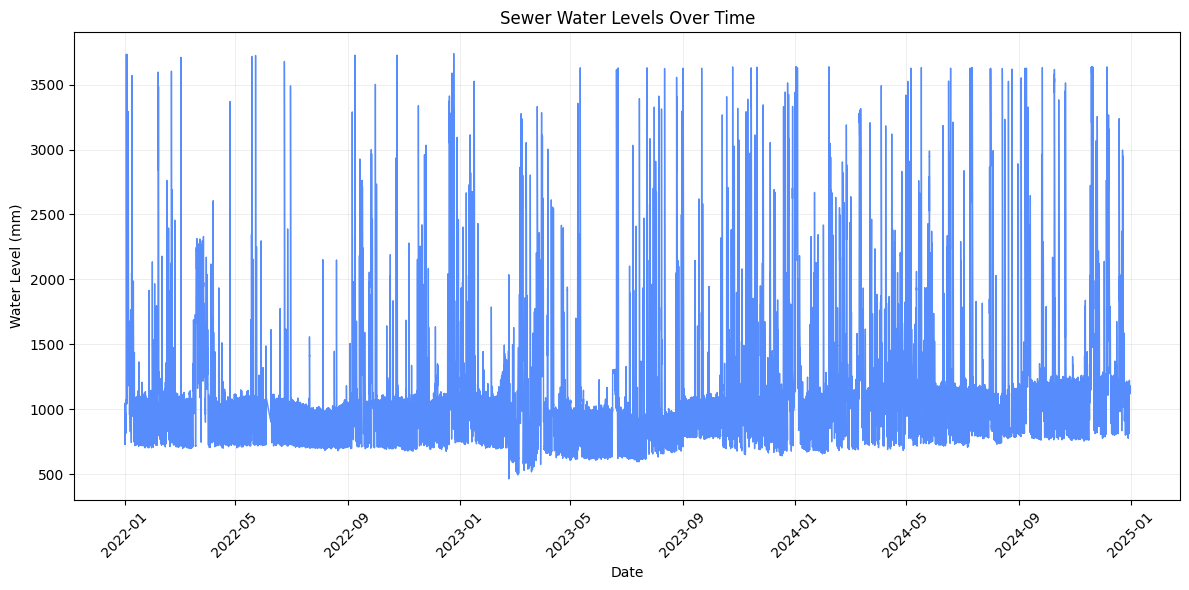

In [375]:
plt.figure(figsize=(12, 6))
plt.plot(sewage_rainfall_df.index, sewage_rainfall_df['waterlevel'], linewidth=1)

plt.xlabel('Date')
plt.ylabel('Water Level (mm)')
plt.title('Sewer Water Levels Over Time')
plt.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

From first glance, we can see that there is a lot of variation of sewer levels, just like the statistics indicated. The sewer levels regularly overflow according to this data. This data also fits well with our assumption of 2024 being the rainiest year, here the waterlevels in 2024 are slightly higher and it seems to have more frequent overflow events as for example 2022.

<Axes: ylabel='Frequency'>

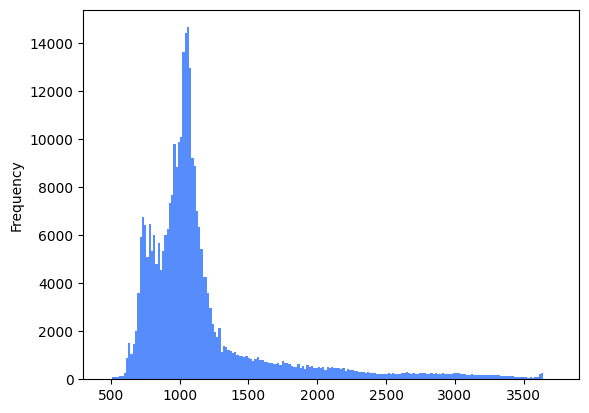

In [376]:
sewage_rainfall_df['waterlevel'].plot.hist(bins=200)

This distribution can be confirmed looking at the histogram of sewer levels: we have a long right tail, we have few present high-level events, likely storm driven surges. As we know the overflow of the sewer happens at 3m, it might be interesting to look at the tail of this data. What about the data above 3m, is it realistic?

<Axes: ylabel='Frequency'>

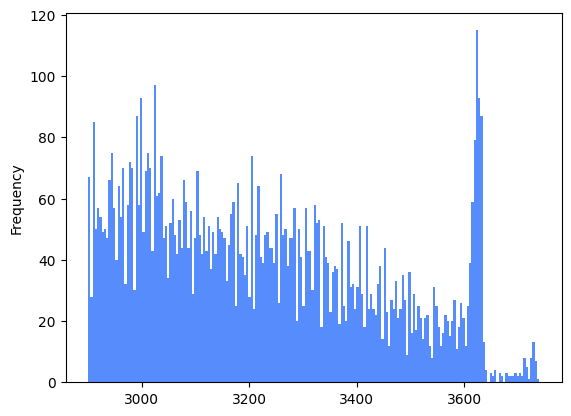

In [377]:
tail = sewage_rainfall_df[sewage_rainfall_df['waterlevel'] > 2900]['waterlevel']
tail.plot.hist(bins=200)

The spike around 3.6-3.7m is suspicious. Let's have a look at the data above 3.6m to see the timing.

In [378]:
limit = 3600
sewer_above_limit = sewage_rainfall_df[(sewage_rainfall_df['waterlevel'] > limit)]

dates = pd.Series(sewer_above_limit.index).dt.date
date_counts = dates.value_counts().sort_index()
print(date_counts)


datetime
2022-01-02    12
2022-01-03    13
2022-02-20     1
2022-03-03     1
2022-05-19    17
2022-05-23     7
2022-06-24     8
2022-09-08     9
2022-10-24     8
2022-12-25    13
2023-05-12     6
2023-06-20     3
2023-06-22    33
2023-07-23    11
2023-07-24    25
2023-08-12     9
2023-09-01    33
2023-09-21    17
2023-10-25     6
2023-11-14     7
2023-11-20    14
2024-01-02    33
2024-01-04     6
2024-02-07    45
2024-05-06     5
2024-05-17    11
2024-06-18     9
2024-07-09    46
2024-07-12    24
2024-08-01    35
2024-08-14    20
2024-08-24     6
2024-09-07    13
2024-09-08     6
2024-09-09     9
2024-09-26     7
2024-10-09     8
2024-11-19    49
2024-11-20    17
2024-11-21     5
2024-12-06     5
Name: count, dtype: int64


Let's spot check some days with very high waterlevels, e.g. the day 2024-07-09 that has 46 datapoints with waterlevel above 3.6m. We can reuse the dataframe created before for this day, since we also analysed the rainfall values for this day. Thus, we plot both together to be able to see the relationship between rainfall and sewage level more clearly.

**NOTE**: In this part of our project, we found a mistake in timestamps between the sewage and the rainfall data that was provided. For the sake of demonstration, we show the following step with the original data, as to prove the point we discovered.

In [379]:
def lineplots_with_shifted_index(data, title):
    # AI help!
    fig, ax = plt.subplots(figsize=(13, 6))
    ax.plot(data.index + pd.Timedelta(hours=1), data['waterlevel'], label='Sewer level (shifted +1h)')
    ax.plot(data.index, data['avant_port_mm'] * 300, color='red', label='Rainfall Avant-Port (scaled)', alpha=0.7)  # scaled to fit on same axis
    ax.plot(data.index, data['flagey_mm'] * 300, color='green', label='Rainfall Flagey (scaled)', alpha=0.7)  # scaled to fit on same axis
    ax.set_title(title)
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.tick_params(axis='x', rotation=90)
    ax.legend()
    plt.show()

def lineplot_daily_rainfall_scaled(data, title):
    fig, ax = plt.subplots(figsize=(13, 6))
    ax.plot(data.index, data['waterlevel'], label='Sewer level')
    ax.plot(data.index, data['avant_port_mm'] * 300, color='red', label='Rainfall Avant-Port (scaled)', alpha=0.7)  # scaled to fit on same axis
    ax.plot(data.index, data['flagey_mm'] * 300, color='green', label='Rainfall Flagey (scaled)', alpha=0.7)  # scaled to fit on same axis
    ax.set_title(title)
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.tick_params(axis='x', rotation=90)
    ax.legend()
    plt.show()

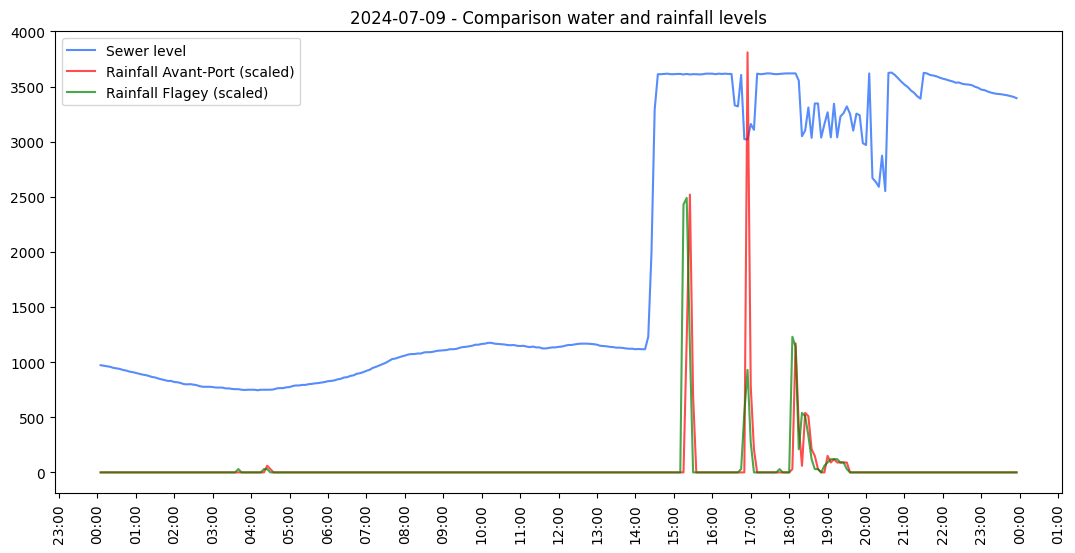

In [380]:
day_2024_07_09_old_timestamps = sewage_rainfall_df_old_timestamp[(sewage_rainfall_df_old_timestamp.index > pd.to_datetime('2024-07-09 0:00')) & (sewage_rainfall_df_old_timestamp.index < pd.to_datetime('2024-07-10 0:00')) ]

lineplot_daily_rainfall_scaled(day_2024_07_09_old_timestamps, '2024-07-09 - Comparison water and rainfall levels')

Interestingly, this selected day overlaps with the day of heavy to violent rainfall that we inspected before. Here both rainfall and sewage was plotted on that day. We do see a rise in both sewage levels and rainfall around the same time. However, it is important to note that the sewage level increased by more than 2 meters around 14:15, although the heavy rain only hit one hour after, at 15:15. Normally, we would expect to see this the other way around, not rain following a sewage increase.

This raised a lot of suspicions. After checking the data of rainfall and sewage online on the interactive map of Hydria (https://hydria.be/interactieve-kaart-meetstations/), we can see that for this day, the rain and the sewer level increased at the same time (i.e. at 16:15). The online data specifies that both rain and sewer use timestamps of UTC+2. Our rainfall data specifies that the timestamps are UTC+1 (see the header we removed in the beginning). Unfortunately, the sewage data we got does not specify its timezone. This made us think that the sewage timezone might be UTC, while the rainfall data works with UTC+1, which garbles the relationship between rainfall and its effect on sewage levels.
 Let's see what happens if we shift the sewage data 1 hour ahead.

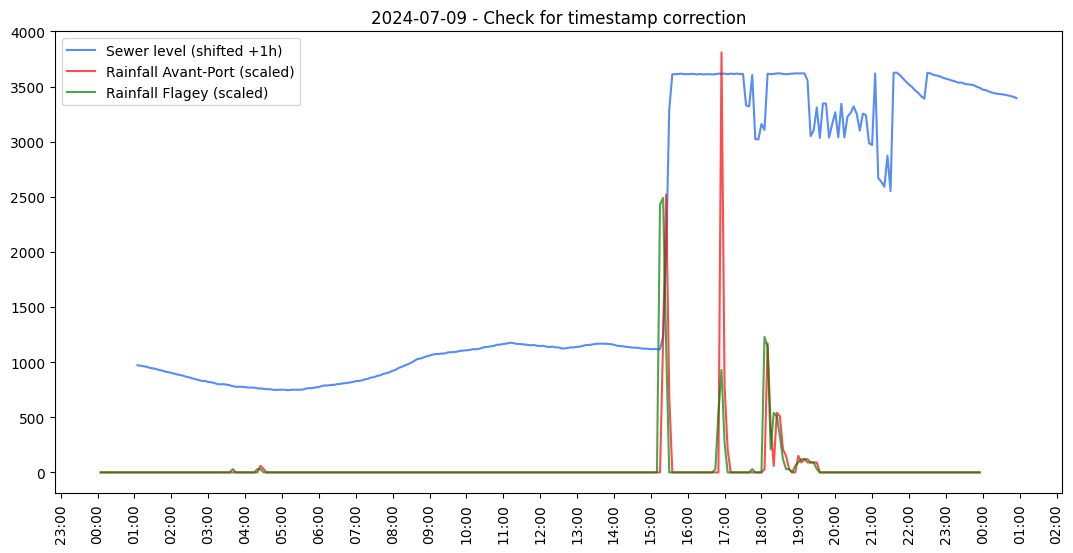

In [381]:
# Test the shift visually
test_index = day_2024_07_09_old_timestamps.index + pd.Timedelta(hours=1)
lineplots_with_shifted_index(day_2024_07_09_old_timestamps, "2024-07-09 - Check for timestamp correction")

In this timestamp corrected plot, we can see very beautifully how the huge spike of rained caused a big increase of waterlevel in a short amount of time. Suddenly the relationship between rain and waterlevel makes much more sense, and fits the data online from the same sensors much better. To confirm this, a few more days with high sewer and rainfall will be plotted and compared to the online data from Hydra.

In [382]:
day_2024_08_01 = sewage_rainfall_df_old_timestamp[(sewage_rainfall_df_old_timestamp.index > pd.to_datetime('2024-08-01 0:00')) & (sewage_rainfall_df_old_timestamp.index < pd.to_datetime('2024-08-02 0:00'))]
day_2023_06_22 = sewage_rainfall_df_old_timestamp[(sewage_rainfall_df_old_timestamp.index > pd.to_datetime('2023-06-22 0:00')) & (sewage_rainfall_df_old_timestamp.index < pd.to_datetime('2023-06-23 0:00'))]


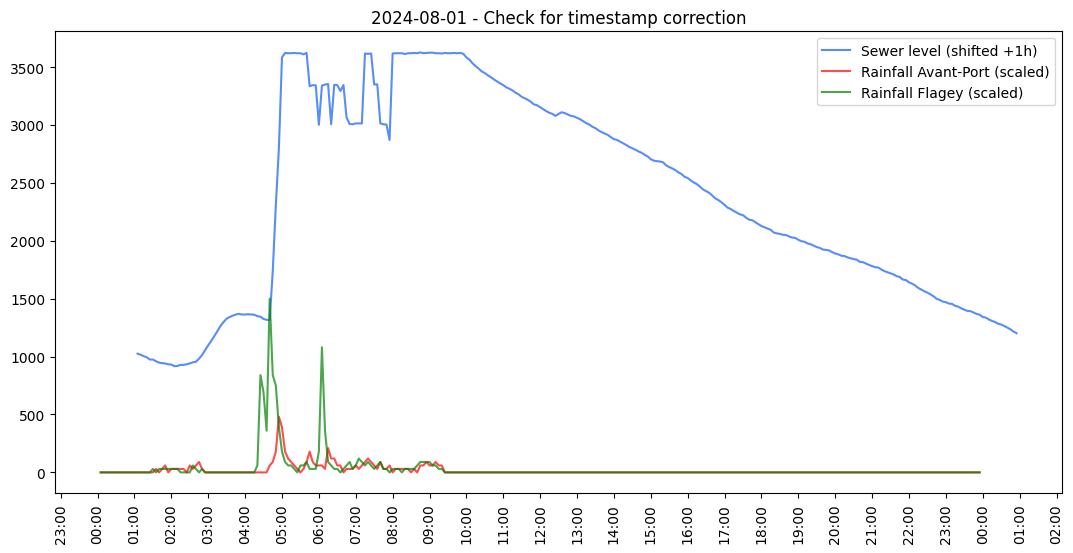

In [383]:
lineplots_with_shifted_index(day_2024_08_01, "2024-08-01 - Check for timestamp correction")

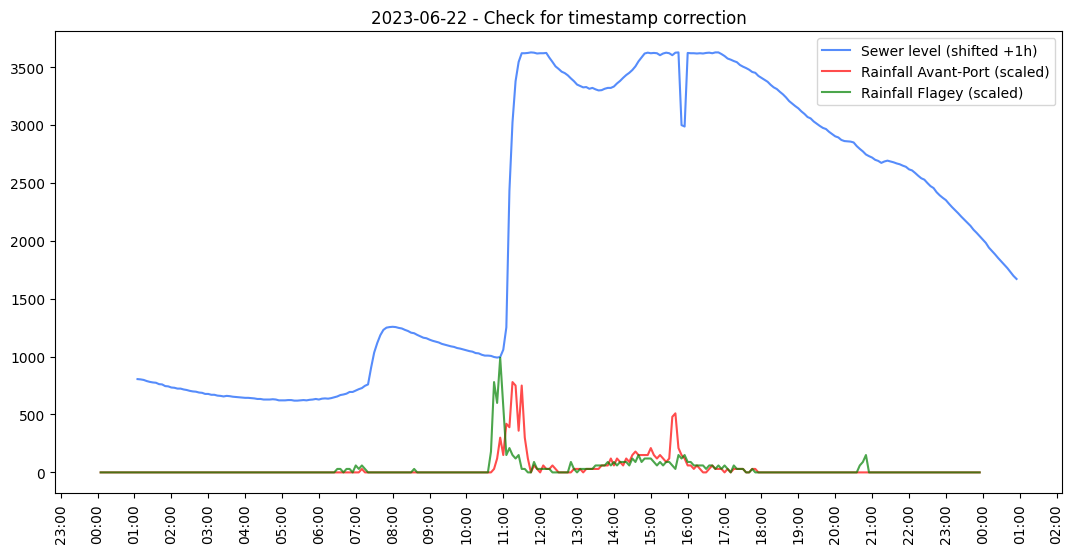

In [384]:
lineplots_with_shifted_index(day_2023_06_22, "2023-06-22 - Check for timestamp correction")

Looking at 3 random days with high rainfall and sewage levels, our suspicions are confirmed. Shifting the sewage timestamp one hour further (+1) results in a relationship that makes much more sense. All 3 days have also been compared to data from the website from the same days. With the timeshift, both rainfall and sewer levels should be UTC+1 timestamp, which fits very well with the online data, where the exact same data is displayed in UTC+2.

For clearness of datasets used: the timestamps were corrected in the data cleaning part and now we have two complete datasets:
- sewage_rainfall_df: has the sewage level timestamp corrected (+1 hour)
- sewage_rainfall_df_old_timestamp: is the original data with mismatched timestamps

For the sake of this project, we will use the corrected timestamp data (sewage_rainfall_df). This is very important so that our models can correcly learn the relationship between rainfall and sewage levels.

Our spot checks of days with high waterlevel all revealed a close visual relationship with high intensity rain around the same time.
In order to check for unrealistic spikes in waterlevel, we will compute the waterlevel change (delta), that will tell us how much the waterlevel rose or fell within 5 minutes.

In [385]:
def make_waterlevel_delta_column(dataset):
    """We do this to make sure that the difference is only calculated when the real timestep is 5 minutes.
    In case our timeseries is missing a timestamp, delta will not be calculated"""
    # AI help
    dataset['time_diff'] = dataset.index.to_series().diff()
    dataset['waterlevel_delta'] = dataset['waterlevel'].diff()
    dataset.loc[dataset['time_diff'] != pd.Timedelta(minutes=5), 'waterlevel_delta'] = np.nan
    dataset = dataset.drop('time_diff', axis=1)
    return dataset

In [386]:
df_eda = sewage_rainfall_df.copy()

df_eda = make_waterlevel_delta_column(df_eda)
# Are there timegaps? We expect some because of the 5 day negative sensor
df_eda['waterlevel_delta'].isna().sum()

np.int64(4)

In [387]:
df_eda = df_eda.dropna()

We remove the 4 values that we could not compute a delta for.

In [388]:
df_eda['waterlevel_delta'].describe()

count    313359.000000
mean          0.001293
std          19.862536
min       -1615.937000
25%          -4.870000
50%           0.000000
75%           2.551000
max        1826.016000
Name: waterlevel_delta, dtype: float64

Just from the statistics of delta levels, we can see that there are big variations in waterlevel in just 5 minutes. The biggest water level increase was 1.8m and the greatest decrease was -1.6m in just 5 minutes. We will have a look at these extreme levels and see if they can visually be explained.

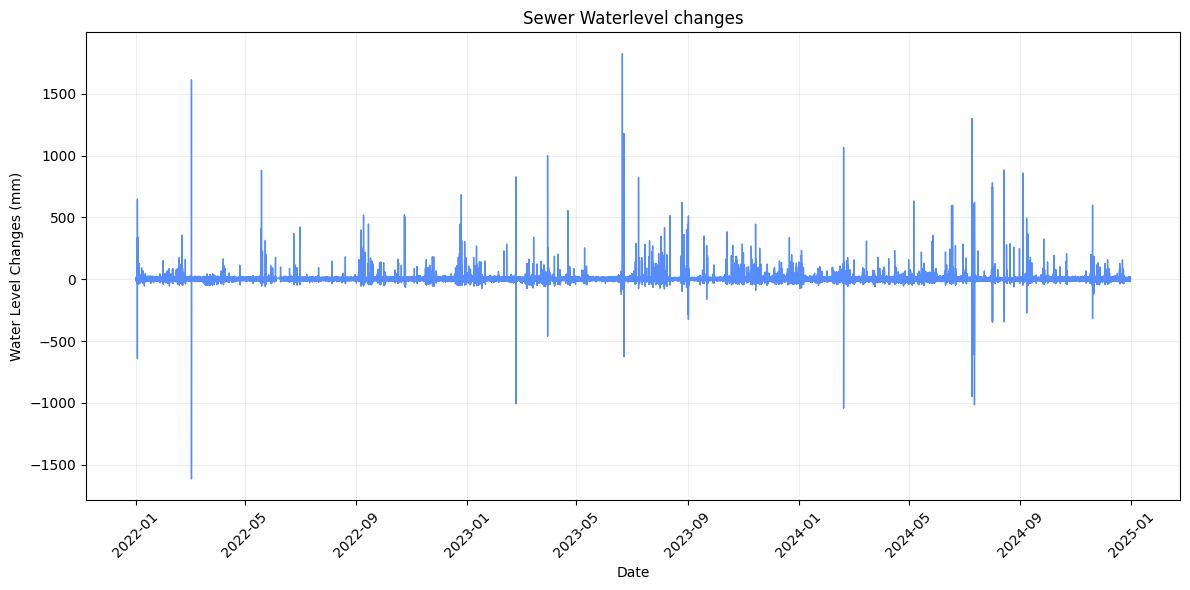

In [389]:
# Create the plot
plt.figure(figsize=(12, 6))
plt.plot(df_eda.index, df_eda['waterlevel_delta'], linewidth=1)

# Add labels and formatting
plt.xlabel('Date')
plt.ylabel('Water Level Changes (mm)')
plt.title('Sewer Waterlevel changes')
plt.grid(True, alpha=0.3)

# Rotate x-axis labels for readability
plt.xticks(rotation=45)
plt.tight_layout()

# Show or save
plt.show()

Looking at this plot of waterlevel changes over 3 years, we can see that there are a few events that have a waterlevel change of above +/-1m. We will have a look at some of these to see what is going on.

In [390]:
df_eda_gt_1m = df_eda.loc[df_eda['waterlevel_delta'].abs() > 1000]
df_eda_gt_1m

,avant_port_mm,flagey_mm,waterlevel,target,waterlevel_delta
datetime,,,,,
2022-03-03 09:05:00,0.0,0.0,2096.382,1011.902,1200.417
2022-03-03 09:15:00,0.0,0.0,3710.000,1021.641,1613.618
2022-03-03 09:20:00,0.0,0.0,2094.063,1031.148,-1615.937
2022-03-03 09:25:00,0.0,0.0,944.195,1028.829,-1149.868
2023-02-23 13:10:00,0.0,0.0,1028.829,986.625,-1007.265
2023-03-30 11:40:00,0.0,0.0,1953.125,1511.019,1000.556
2023-06-20 18:55:00,1.1,0.6,2996.459,3518.177,1826.016
2023-06-22 11:10:00,1.3,0.7,2431.148,3622.058,1178.621
2024-02-19 09:15:00,0.0,0.0,2042.293,1054.506,1067.552


Since the 3rd March 2022 has 4 values of waterlevel change above 1m, two of them even above 1.5m within 5 minutes, we will have a look at that day. Other days with more than one value above 1m are the 19th February 2023 and 9th July 2024. It should be noted that the 9th July was already investigated when checking our timestamp issue, just before. So here we will have a look at the two other days.

In [391]:
day_2022_03_03 = df_eda[(df_eda.index > pd.to_datetime('2022-03-03 0:00')) & (df_eda.index < pd.to_datetime('2022-03-04 0:00'))]
day_2024_02_19 = df_eda[(df_eda.index > pd.to_datetime('2024-02-19 0:00')) & (df_eda.index < pd.to_datetime('2024-02-20 0:00'))]
day_2024_07_12 = df_eda[(df_eda.index > pd.to_datetime('2024-07-12 0:00')) & (df_eda.index < pd.to_datetime('2024-07-13 0:00'))]
day_2023_06_22 = df_eda[(df_eda.index > pd.to_datetime('2023-06-22 0:00')) & (df_eda.index < pd.to_datetime('2023-06-23 0:00'))]
day_2023_06_20 = df_eda[(df_eda.index > pd.to_datetime('2023-06-20 0:00')) & (df_eda.index < pd.to_datetime('2023-06-21 0:00'))]
day_2023_03_30 = df_eda[(df_eda.index > pd.to_datetime('2023-03-30 0:00')) & (df_eda.index < pd.to_datetime('2023-03-31 0:00'))]
day_2023_02_23 = df_eda[(df_eda.index > pd.to_datetime('2023-02-23 0:00')) & (df_eda.index < pd.to_datetime('2023-02-24 0:00'))]


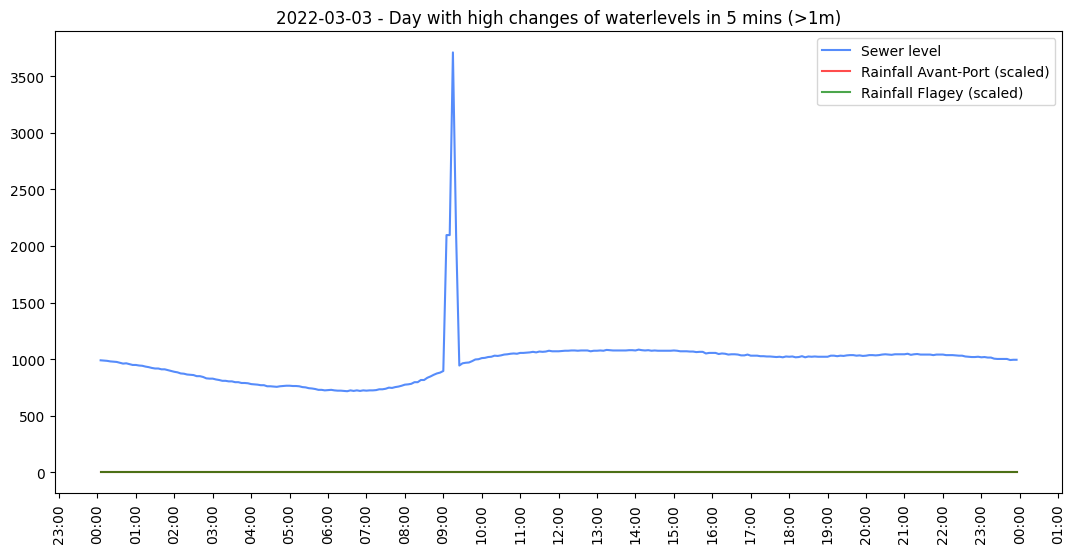

In [392]:

lineplot_daily_rainfall_scaled(day_2022_03_03, "2022-03-03 - Day with high changes of waterlevels in 5 mins (>1m)")

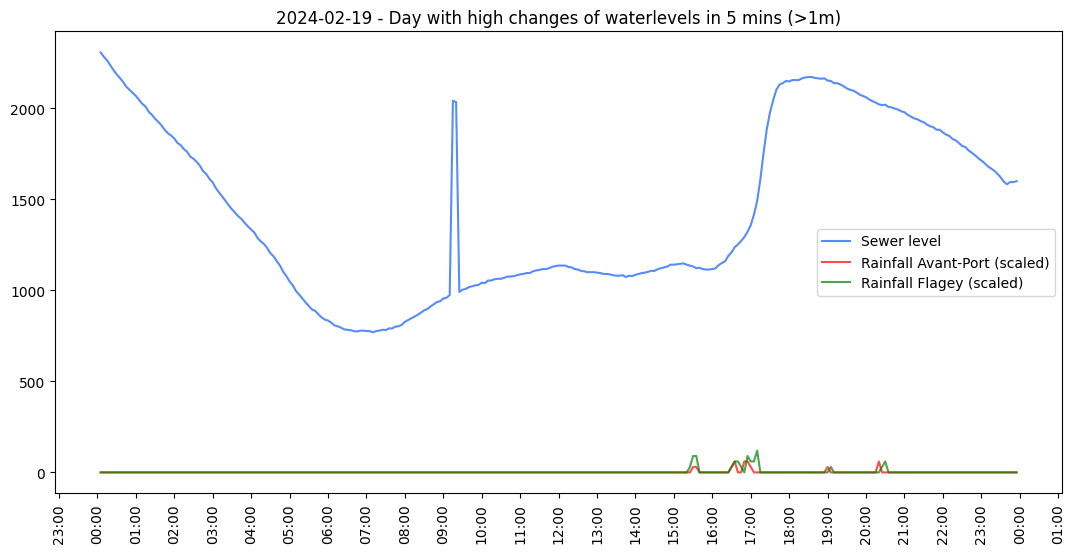

In [393]:
lineplot_daily_rainfall_scaled(day_2024_02_19, "2024-02-19 - Day with high changes of waterlevels in 5 mins (>1m)")

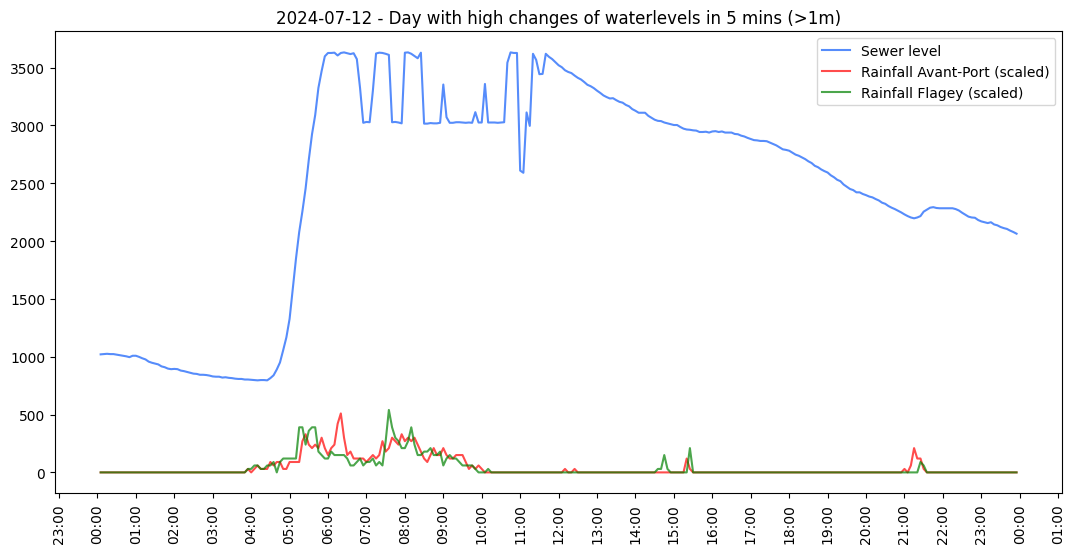

In [394]:
lineplot_daily_rainfall_scaled(day_2024_07_12, "2024-07-12 - Day with high changes of waterlevels in 5 mins (>1m)")

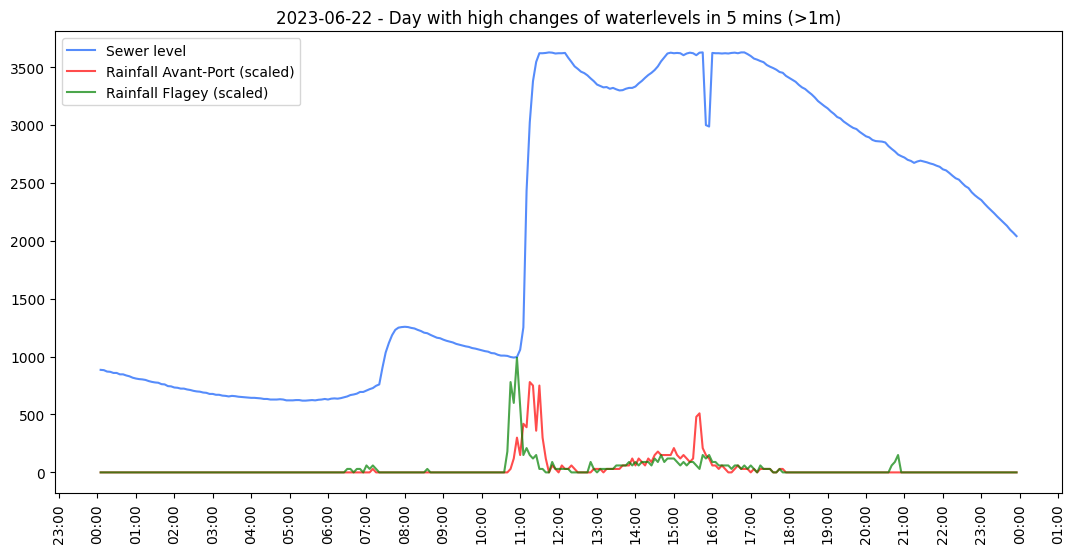

In [395]:
lineplot_daily_rainfall_scaled(day_2023_06_22, "2023-06-22 - Day with high changes of waterlevels in 5 mins (>1m)")


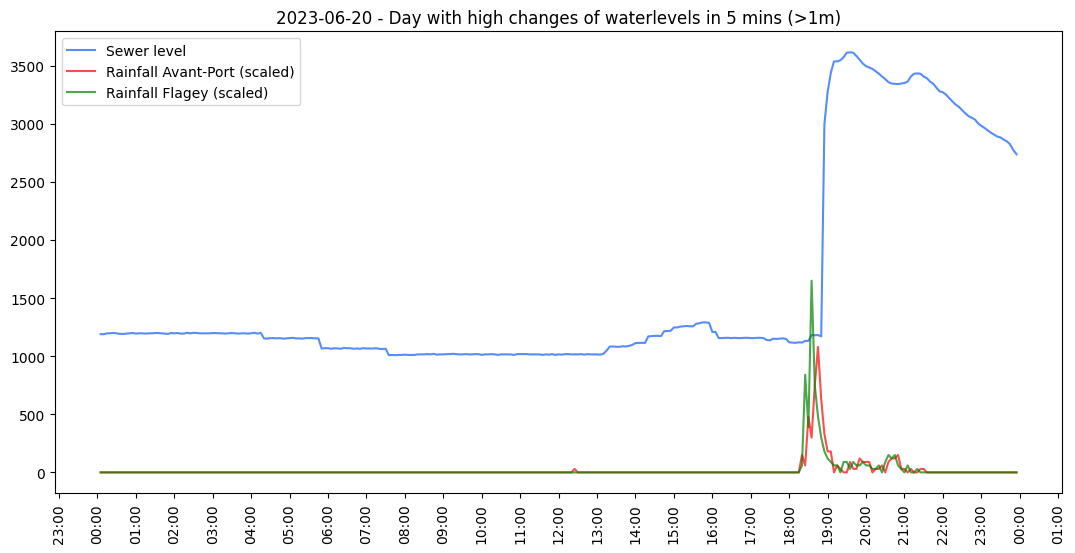

In [396]:
lineplot_daily_rainfall_scaled(day_2023_06_20, "2023-06-20 - Day with high changes of waterlevels in 5 mins (>1m)")


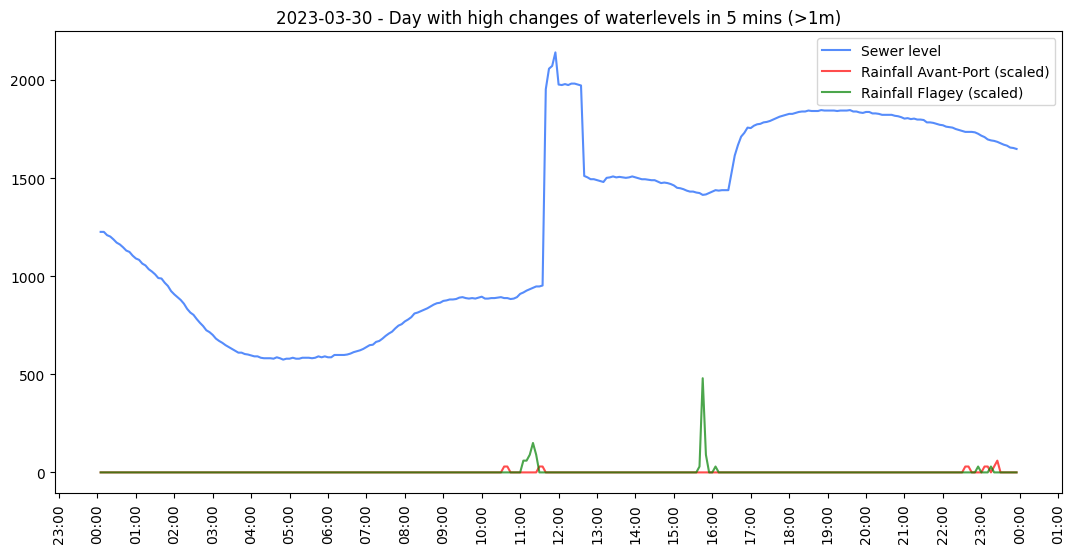

In [397]:
lineplot_daily_rainfall_scaled(day_2023_03_30, "2023-03-30 - Day with high changes of waterlevels in 5 mins (>1m)")

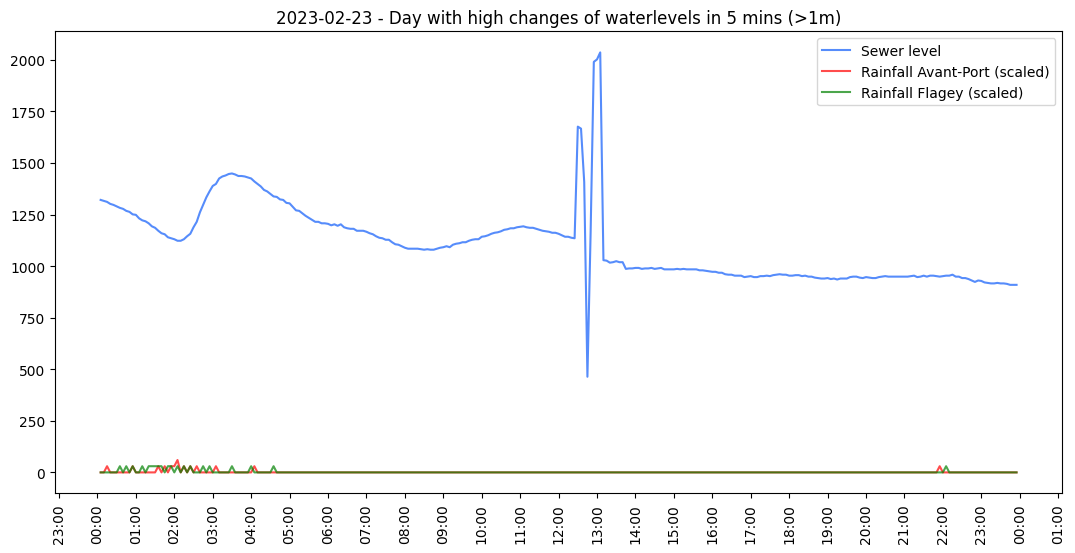

In [398]:
lineplot_daily_rainfall_scaled(day_2023_02_23, "2023-02-23 - Day with high changes of waterlevels in 5 mins (>1m)")

Out of all days with intense spikes, most of them look plausible when being plotted with rain. The intense changes in waterlevel occur mostly at the same time or just after rain being present. There are three days that look abnormal: 3rd March 2022, 19th Feb 2024 and 23rd Feb 2023. These days include intense spikes in an otherwise very smooth waterlevel pattern and no rain at all is present during the time, some not even during the day. All of these look like they could be interpolated.

In [399]:
def plot_3_abnormalities_in_waterlevel_change(dataset):

    day_2022_03_03_abnormality = dataset[(dataset.index > pd.to_datetime('2022-03-03 8:50')) & (dataset.index < pd.to_datetime('2022-03-03 9:35'))]
    day_2024_02_19_abnormality = dataset[(dataset.index > pd.to_datetime('2024-02-19 9:00')) & (dataset.index < pd.to_datetime('2024-02-19 9:35'))]
    day_2023_02_23_abnormality = dataset[(dataset.index > pd.to_datetime('2023-02-23 12:15')) & (dataset.index < pd.to_datetime('2023-02-23 13:25'))]

    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 8))

    ax1.plot(day_2022_03_03_abnormality.index, day_2022_03_03_abnormality['waterlevel'], label='Sewer level')
    ax1.plot(day_2022_03_03_abnormality.index, day_2022_03_03_abnormality['avant_port_mm'] * 300, color='red', label='Rainfall Avant-Port (scaled)', alpha=0.7)
    ax1.plot(day_2022_03_03_abnormality.index, day_2022_03_03_abnormality['flagey_mm'] * 300, color='green', label='Rainfall Flagey (scaled)', alpha=0.7)
    ax1.set_title("2022-03-03 Abnormal moments")
    ax1.tick_params(axis='x', rotation=90)
    ax1.grid()

    ax2.plot(day_2024_02_19_abnormality.index, day_2024_02_19_abnormality['waterlevel'], label='Sewer level')
    ax2.plot(day_2024_02_19_abnormality.index, day_2024_02_19_abnormality['avant_port_mm'] * 300, color='red', label='Rainfall Avant-Port (scaled)', alpha=0.7)
    ax2.plot(day_2024_02_19_abnormality.index, day_2024_02_19_abnormality['flagey_mm'] * 300, color='green', label='Rainfall Flagey (scaled)', alpha=0.7)
    ax2.set_title("2024-02-19 Abnormal moments")
    ax2.tick_params(axis='x', rotation=90)
    ax2.grid()

    ax3.plot(day_2023_02_23_abnormality.index, day_2023_02_23_abnormality['waterlevel'], label='Sewer level')
    ax3.plot(day_2023_02_23_abnormality.index, day_2023_02_23_abnormality['avant_port_mm'] * 300, color='red', label='Rainfall Avant-Port (scaled)', alpha=0.7)
    ax3.plot(day_2023_02_23_abnormality.index, day_2023_02_23_abnormality['flagey_mm'] * 300, color='green', label='Rainfall Flagey (scaled)', alpha=0.7)
    ax3.set_title("2023-02-23 Abnormal moments")
    ax3.tick_params(axis='x', rotation=90)
    ax3.grid()

    # AI help with spacing
    # Shared legend at the top
    handles, labels = ax1.get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.02))
    # Increase spacing between subplots
    plt.subplots_adjust(hspace=0.8, top=0.92)

    plt.show()

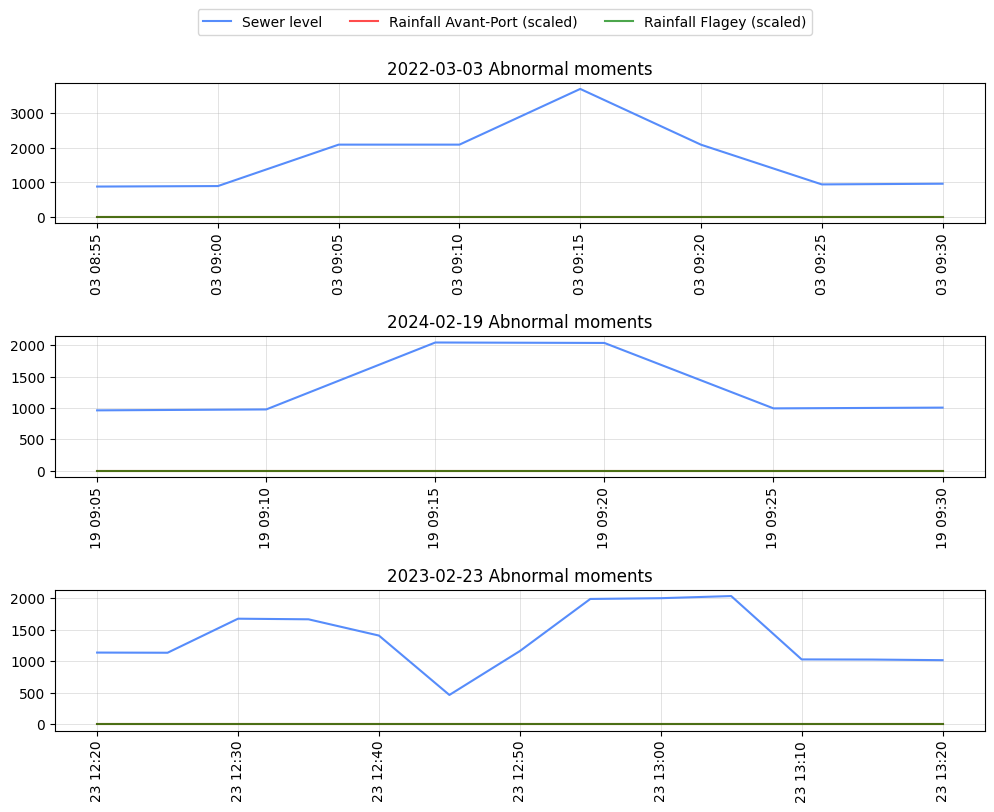

In [400]:
plot_3_abnormalities_in_waterlevel_change(sewage_rainfall_df)

Values to interpolate:
- 2022-03-03, we will interpolate the spikes, aka any values above 1m.
- 2024-02-19, we will interpolate the values above 1.5m
- 2023-02-23, we will interpolate values above 1.3m and below 0.6m.

In [401]:
sewage_rainfall_df.isna().sum()

avant_port_mm    0
flagey_mm        0
waterlevel       0
target           0
dtype: int64

Before interpolation, there are no missing values, so we can go ahead.

In [402]:
# create masks for all 3 days as explained above
mask_2022_03_03 = ((sewage_rainfall_df.index > pd.to_datetime('2022-03-03 8:50')) & (sewage_rainfall_df.index < pd.to_datetime('2022-03-03 9:35'))
    & (sewage_rainfall_df['waterlevel'] > 1000))
mask_2024_02_19 = ((sewage_rainfall_df.index > pd.to_datetime('2024-02-19 9:00')) & (sewage_rainfall_df.index < pd.to_datetime('2024-02-19 9:35'))
    & (sewage_rainfall_df['waterlevel'] > 1500))
mask_2023_02_23 = ((sewage_rainfall_df.index > pd.to_datetime('2023-02-23 12:15')) & (sewage_rainfall_df.index < pd.to_datetime('2023-02-23 13:25'))
    & ((sewage_rainfall_df['waterlevel'] > 1300) | ((sewage_rainfall_df['waterlevel'] < 600))))

# set all masks to NaN
sewage_rainfall_df.loc[mask_2022_03_03, 'waterlevel'] = np.nan
sewage_rainfall_df.loc[mask_2024_02_19, 'waterlevel'] = np.nan
sewage_rainfall_df.loc[mask_2023_02_23, 'waterlevel'] = np.nan

print("NaNs before interpolation: ", sewage_rainfall_df['waterlevel'].isna().sum())

# interpolate
sewage_rainfall_df['waterlevel'] = sewage_rainfall_df['waterlevel'].interpolate(method='linear')

# check how many NaNs after (should be 0)
print("NaNs after interpolation: ", sewage_rainfall_df['waterlevel'].isna().sum())

NaNs before interpolation:  13
NaNs after interpolation:  0


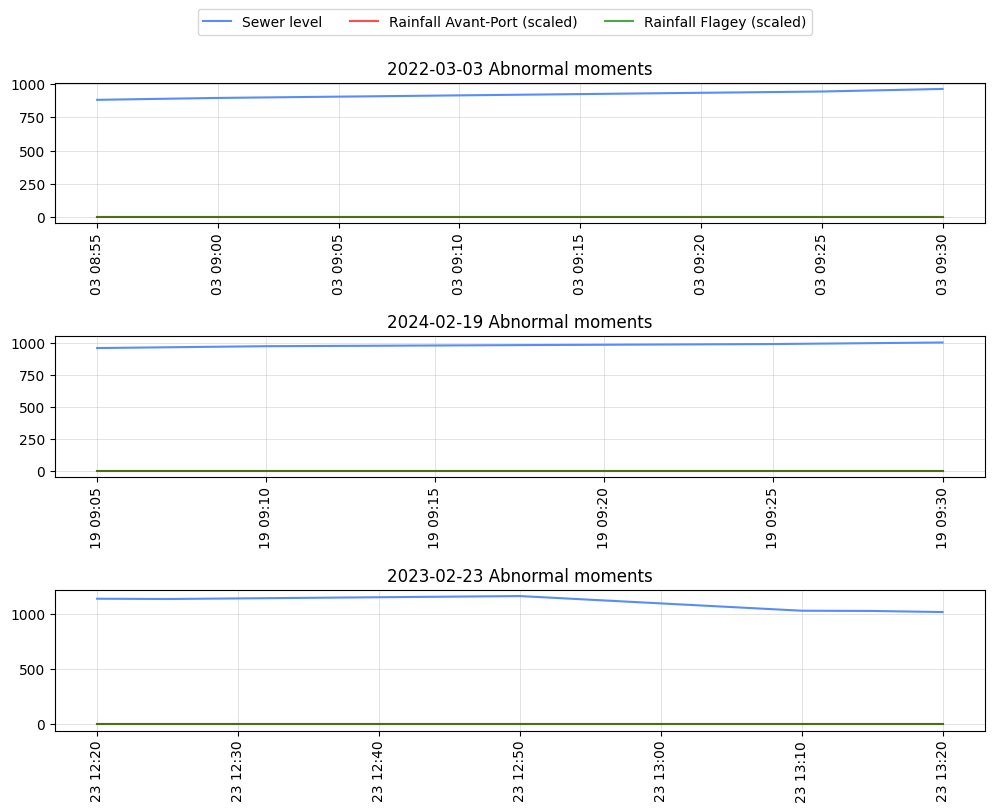

In [403]:
plot_3_abnormalities_in_waterlevel_change(sewage_rainfall_df)

It looks like the spikes have been removed and interpolated correctly. We can continue with our EDA, since outliers have been dealt with.

### Temporal patterns

Sewage data is highly dependent on temporal patterns: even though we only have rainfall data as an independent variable, we can create meaningful features out of the sewer data itself. Hourly patterns for example could help the model learn the temporal patterns of water usage that affects the sewer level throughout the day. Similarly, water usage can differ depending on the day of the week (e.g. weekday vs. weekend) but also depending on the season, since people might be using more water usage in winter (for example used for heating).

In [404]:
df_eda['hour'] = df_eda.index.hour
df_eda['weekday'] = df_eda.index.dayofweek
df_eda['month'] = df_eda.index.month
df_eda.head()

,avant_port_mm,flagey_mm,waterlevel,target,waterlevel_delta,hour,weekday,month
datetime,,,,,,,,
2022-01-01 01:05:00,0.0,0.0,881.589,857.242,-2.319,1,5,1
2022-01-01 01:10:00,0.0,0.0,881.589,857.242,0.000,1,5,1
2022-01-01 01:15:00,0.0,0.0,871.850,859.792,-9.739,1,5,1
2022-01-01 01:20:00,0.0,0.0,876.719,854.923,4.869,1,5,1
2022-01-01 01:25:00,0.0,0.0,871.850,854.923,-4.869,1,5,1


In [405]:
hourly_pattern = df_eda.groupby(by='hour').agg({'waterlevel': 'mean', 'avant_port_mm': 'mean', 'flagey_mm': 'mean'})
hourly_pattern.head()

,waterlevel,avant_port_mm,flagey_mm
hour,,,
0,1191.195708,0.007197,0.006667
1,1124.851263,0.005730,0.005692
2,1055.060550,0.006725,0.005936
3,1002.972140,0.009069,0.008670
4,965.957662,0.007613,0.009697


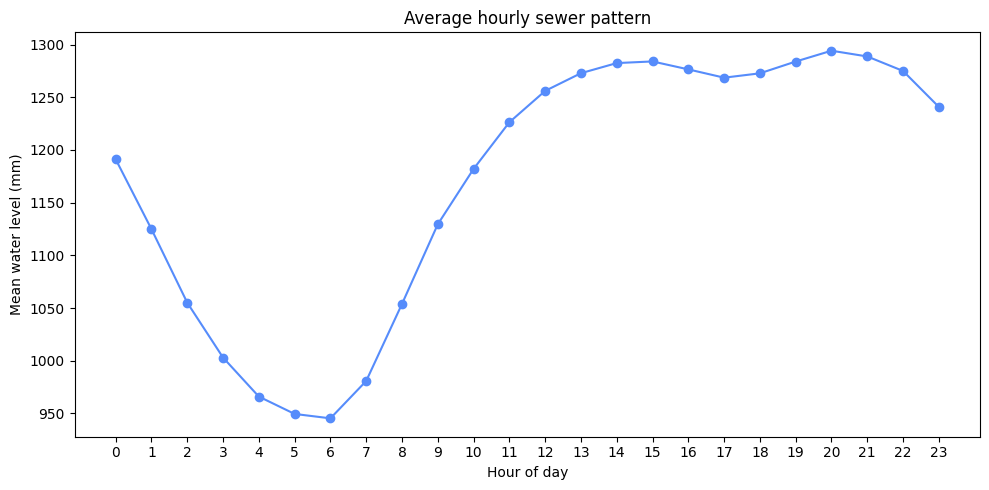

In [406]:
plt.figure(figsize=(10, 5))
plt.plot(hourly_pattern.index, hourly_pattern['waterlevel'], marker='o')
plt.xlabel('Hour of day')
plt.ylabel('Mean water level (mm)')
plt.title('Average hourly sewer pattern')
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()


In [407]:
hourly_by_weekday = df_eda.groupby(['weekday', 'hour']).agg({'waterlevel': 'mean', 'avant_port_mm': 'mean', 'flagey_mm': 'mean'})
hourly_by_weekday.head()

waterlevel  avant_port_mm  flagey_mm
weekday hour                                       
0       0     1181.049825       0.002151   0.002634
        1     1103.126816       0.005879   0.005024
        2     1035.206389       0.007639   0.006624
        3      990.646649       0.009882   0.013408
        4      956.308084       0.007318   0.009615

From this plot, we can see a clear pattern of sewer levels throughout the day. The sewer empties in the night, when less water is used generally and fills up gradually in the morning until it has reached a quite stable level around 13:00, that is maintained with a few fluctuations until later in the evening around 22:00. This could be important to feed our models, since predicting sewer waterlevels in the night or during the day can differ greatly.

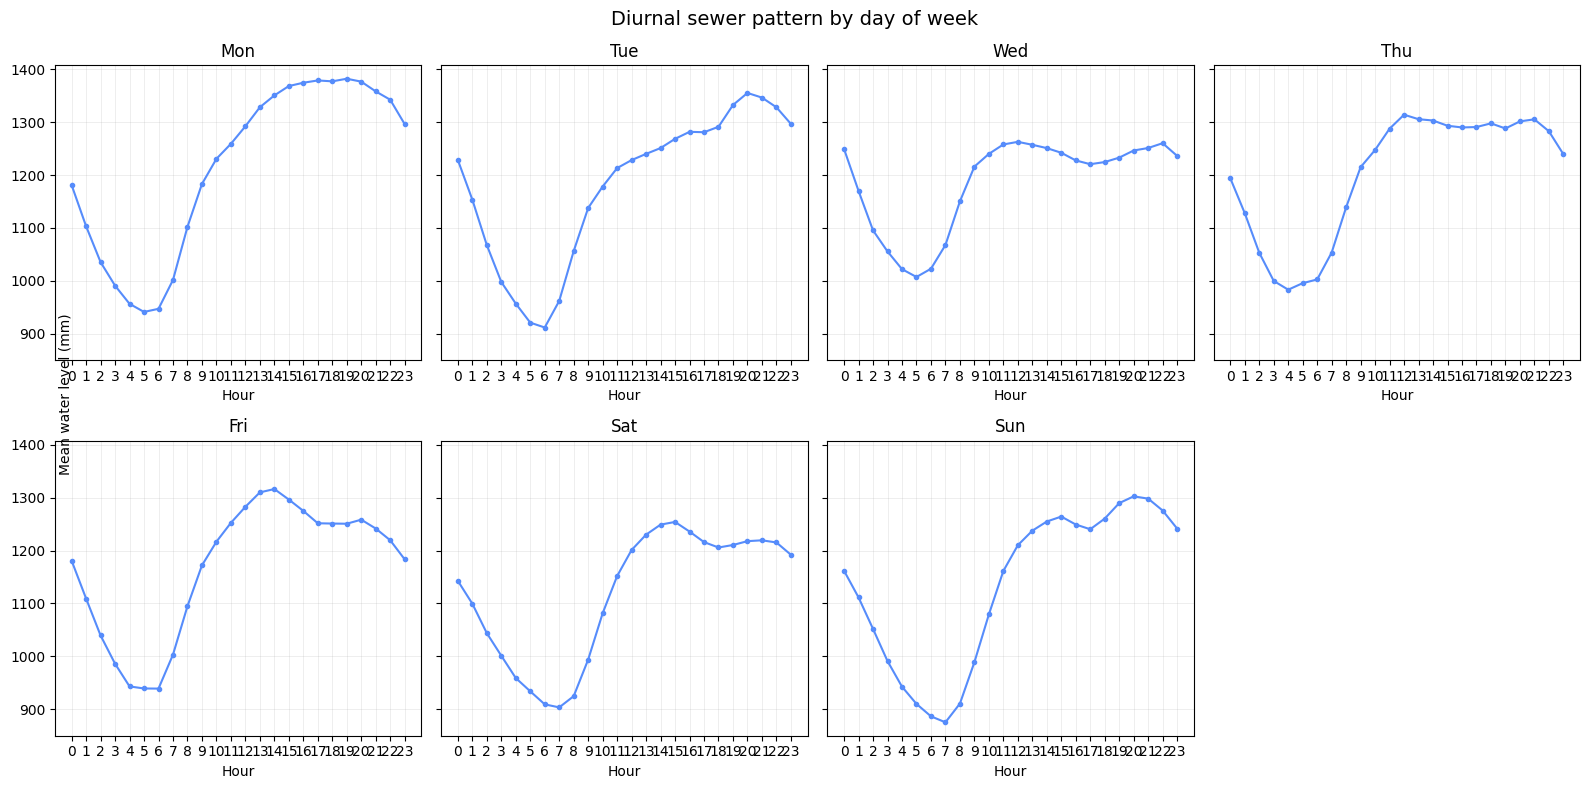

In [408]:
# NOTE : AI generated plots

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)
axes = axes.flatten()  # easier to iterate
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
for dayofweek in range(7):
    ax = axes[dayofweek]
    data = hourly_by_weekday.loc[dayofweek]
    ax.plot(data.index, data['waterlevel'], marker='o', markersize=3)
    ax.set_title(days[dayofweek])
    ax.set_xlabel('Hour')
    ax.set_xticks(range(0, 24))
    ax.grid(True, alpha=0.3)
# Hide the 8th subplot (unused)
axes[7].set_visible(False)
# Shared y-label
fig.text(0.04, 0.5, 'Mean water level (mm)', va='center', rotation='vertical')
fig.suptitle('Diurnal sewer pattern by day of week', fontsize=14)
plt.tight_layout()
plt.show()

Diurnal sewer patterns look very similar in different days of the week. Most days have an increase until after lunch time, some a short decrease around the afternoon and another increase in the evening until levels drop for the night. Since the difference between days is not very significant,creating a feature based on weekday might not add much to our model.

In [409]:
hourly_by_month = df_eda.groupby(['month', 'hour']).agg({'waterlevel': 'mean', 'avant_port_mm': 'mean', 'flagey_mm': 'mean'})
hourly_by_month.head()

waterlevel  avant_port_mm  flagey_mm
month hour                                       
1     0     1285.986257       0.007593   0.009352
      1     1226.129171       0.010153   0.009524
      2     1167.600274       0.008513   0.007348
      3     1106.261038       0.009857   0.011022
      4     1071.570369       0.008871   0.008423

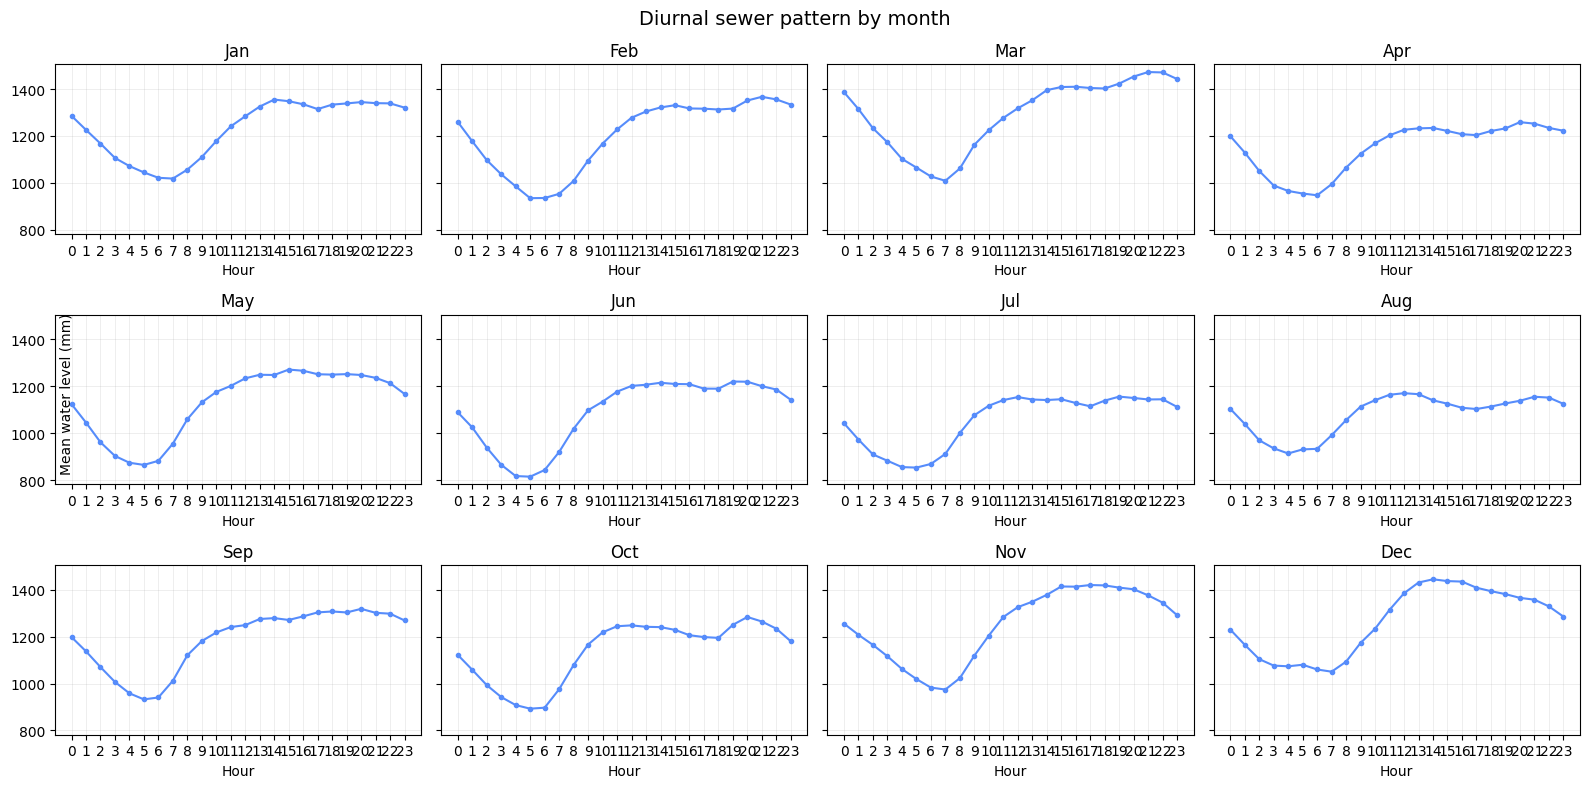

In [410]:
fig, axes = plt.subplots(3, 4, figsize=(16, 8), sharey=True)
axes = axes.flatten()  # easier to iterate
days = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
for month in range(1,13):
    ax = axes[month-1]
    data = hourly_by_month.loc[month]
    ax.plot(data.index, data['waterlevel'], marker='o', markersize=3)
    ax.set_title(days[month-1])
    ax.set_xlabel('Hour')
    ax.set_xticks(range(0, 24))
    ax.grid(True, alpha=0.3)
# Shared y-label
fig.text(0.04, 0.5, 'Mean water level (mm)', va='center', rotation='vertical')
fig.suptitle('Diurnal sewer pattern by month', fontsize=14)
plt.tight_layout()
plt.show()

As expected, you can see a slight difference in waterlevels depending on the month. Generally, in colder months, the maximum of sewer level is higher, which could be explained by higher water usage due to heating. In the summer, from about June to August the average waterlevel generally stays below 1.2m. Feeding our models a feature related to months or seasons could therefore be useful in addition to hour of the day.

# Feature Engineering

In this section, we will use our knowledge gained from the EDA to create the most important features.

## Temporal relationships
As we saw in our EDA, the hour has a high impact on sewage level and the month as well. In order to encode the cyclic characteristic of time (Dec being close to Jan, 24:59h being close to 0:00h), we use sin and cos transformations. 

In [411]:
# Transformers from : https://developer.nvidia.com/blog/three-approaches-to-encoding-time-information-as-features-for-ml-models/

def sin_transformer(period):
	return FunctionTransformer(lambda x: np.sin(x / period * 2 * np.pi))

def cos_transformer(period):
	return FunctionTransformer(lambda x: np.cos(x / period * 2 * np.pi))

def encode_seasonality(dataset):
    dataset['month'] = dataset.index.month
    dataset["month_sin"] = sin_transformer(12).fit_transform(dataset)["month"]
    dataset["month_cos"] = cos_transformer(12).fit_transform(dataset)["month"]

    return dataset

def encode_hourly_circularity(dataset):
    dataset['hour'] = dataset.index.hour
    dataset["hour_sin"] = sin_transformer(24).fit_transform(dataset)["hour"]
    dataset["hour_cos"] = cos_transformer(24).fit_transform(dataset)["hour"]
    return dataset

def encode_circular_relationships(dataset):
    dataset = encode_seasonality(dataset)
    dataset = encode_hourly_circularity(dataset)
    dataset = dataset.drop(['hour', 'month'], axis=1)
    return dataset


In [412]:
# Add monthly for seasonality & hourly for diurnal patterns
sewage_rainfall_df = encode_circular_relationships(sewage_rainfall_df)
sewage_rainfall_15min_df = encode_circular_relationships(sewage_rainfall_15min_df)

In [413]:
sewage_rainfall_df.head()

,avant_port_mm,flagey_mm,waterlevel,target,month_sin,month_cos,hour_sin,hour_cos
datetime,,,,,,,,
2022-01-01 01:00:00,0.0,0.0,883.908,862.111,0.5,0.866025,0.258819,0.965926
2022-01-01 01:05:00,0.0,0.0,881.589,857.242,0.5,0.866025,0.258819,0.965926
2022-01-01 01:10:00,0.0,0.0,881.589,857.242,0.5,0.866025,0.258819,0.965926
2022-01-01 01:15:00,0.0,0.0,871.850,859.792,0.5,0.866025,0.258819,0.965926
2022-01-01 01:20:00,0.0,0.0,876.719,854.923,0.5,0.866025,0.258819,0.965926


## Rain features

**Rain lags** The most important rain lags were shifted by 30 and 60 minutes.

**Accumulated rainfall** For accumulated rainfall, the most correlated window was 7 hours, 420mins.

-> Let's add these.

In [414]:
def add_rainfall_lag_features(dataset):
    """We add different timelags"""
    lag_f = LagFeatures(variables = ["avant_port_mm", "flagey_mm"], freq=["15min", "30min", "60min", "90min"])
    dataset = lag_f.fit_transform(dataset)
    # We have to remove rows with NaN, for the other features to be created correctly
    dataset = dataset.dropna()
    return dataset

def add_rainfall_window_sum_features(dataset):
    """We add different windows"""

    win_f = WindowFeatures(variables=["avant_port_mm", "flagey_mm"], window=["60min", "120min", "180min", "240min", "300min", "360min", "420min", "480min", "540min"], functions=["sum"])
    dataset = win_f.fit_transform(dataset)
    # We have to remove rows with NaN, for the other features to be created correctly
    dataset = dataset.dropna()
    return dataset

In [415]:
sewage_rainfall_df = add_rainfall_lag_features(sewage_rainfall_df)
sewage_rainfall_df = add_rainfall_window_sum_features(sewage_rainfall_df)

sewage_rainfall_15min_df = add_rainfall_lag_features(sewage_rainfall_15min_df)
sewage_rainfall_15min_df = add_rainfall_window_sum_features(sewage_rainfall_15min_df)

In [416]:
sewage_rainfall_df.head()

,avant_port_mm,flagey_mm,waterlevel,target,month_sin,month_cos,hour_sin,hour_cos,avant_port_mm_lag_15min,flagey_mm_lag_15min,...,avant_port_mm_window_300min_sum,flagey_mm_window_300min_sum,avant_port_mm_window_360min_sum,flagey_mm_window_360min_sum,avant_port_mm_window_420min_sum,flagey_mm_window_420min_sum,avant_port_mm_window_480min_sum,flagey_mm_window_480min_sum,avant_port_mm_window_540min_sum,flagey_mm_window_540min_sum
datetime,,,,,,,,,,,,,,,,,,,,,
2022-01-01 02:35:00,0.0,0.0,850.054,842.866,0.5,0.866025,0.5,0.866025,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2022-01-01 02:40:00,0.0,0.0,850.054,840.547,0.5,0.866025,0.5,0.866025,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2022-01-01 02:45:00,0.0,0.0,847.735,837.996,0.5,0.866025,0.5,0.866025,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2022-01-01 02:50:00,0.0,0.0,850.054,835.678,0.5,0.866025,0.5,0.866025,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2022-01-01 02:55:00,0.0,0.0,850.054,835.678,0.5,0.866025,0.5,0.866025,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Waterlevel features

Since the delta of waterlevel can be a good indicator to see whether the sewage basin is filling or water level is decreasing, the delta will also be included as a feature.

In [417]:
sewage_rainfall_df = make_waterlevel_delta_column(sewage_rainfall_df)
sewage_rainfall_15min_df = make_waterlevel_delta_column(sewage_rainfall_15min_df)

In [418]:
sewage_rainfall_df

,avant_port_mm,flagey_mm,waterlevel,target,month_sin,month_cos,hour_sin,hour_cos,avant_port_mm_lag_15min,flagey_mm_lag_15min,...,flagey_mm_window_300min_sum,avant_port_mm_window_360min_sum,flagey_mm_window_360min_sum,avant_port_mm_window_420min_sum,flagey_mm_window_420min_sum,avant_port_mm_window_480min_sum,flagey_mm_window_480min_sum,avant_port_mm_window_540min_sum,flagey_mm_window_540min_sum,waterlevel_delta
datetime,,,,,,,,,,,,,,,,,,,,,
2022-01-01 02:35:00,0.0,0.0,850.054,842.866,5.000000e-01,0.866025,0.500000,0.866025,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
2022-01-01 02:40:00,0.0,0.0,850.054,840.547,5.000000e-01,0.866025,0.500000,0.866025,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000
2022-01-01 02:45:00,0.0,0.0,847.735,837.996,5.000000e-01,0.866025,0.500000,0.866025,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-2.319
2022-01-01 02:50:00,0.0,0.0,850.054,835.678,5.000000e-01,0.866025,0.500000,0.866025,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.319
2022-01-01 02:55:00,0.0,0.0,850.054,835.678,5.000000e-01,0.866025,0.500000,0.866025,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-30 23:35:00,0.0,0.0,1131.720,1124.532,-2.449294e-16,1.000000,-0.258819,0.965926,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.319
2024-12-30 23:40:00,0.0,0.0,1143.777,1126.851,-2.449294e-16,1.000000,-0.258819,0.965926,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.057
2024-12-30 23:45:00,0.0,0.0,1141.459,1124.532,-2.449294e-16,1.000000,-0.258819,0.965926,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-2.318


In [419]:
# we drop the columns that include NaNs
sewage_rainfall_df = sewage_rainfall_df.dropna()
sewage_rainfall_15min_df = sewage_rainfall_15min_df.dropna()


# Model

## Splitting data

We split the dataset into training/validation and test sets while respecting the time order, since this is time series data and shuffling would break the temporal structure. The most recent 20% of the data is kept as the test set, and the remaining 80% is used for training and validation.

In [420]:
df_train_val, df_test = train_test_split(sewage_rainfall_df, test_size=0.2, shuffle=False)

X_train/y_train are separated for the same reason as above.

In [421]:
X_train_val = df_train_val.drop(columns=['target'])
y_train_val = df_train_val['target']

X_test = df_test.drop(columns=['target'])
y_test = df_test['target']

Furthermore, it will be split into a train and validation set the most recent 25% of the data is kept as the validation set, and the remaining 75% as the training set.

In [422]:
df_train, df_val = train_test_split(df_train_val, test_size=0.25, shuffle=False)

In [423]:
X_train = df_train.drop(columns=['target'])
y_train = df_train['target']

X_val = df_val.drop(columns=['target'])
y_val = df_val['target']

We do the same for the 15 minutes as well.

In [424]:
df_train_val_15min, df_test_15min = train_test_split(sewage_rainfall_15min_df, test_size=0.2, shuffle=False)

In [425]:
X_train_val_15min = df_train_val_15min.drop(columns=['target'])
y_train_val_15min = df_train_val_15min['target']

X_test_15min = df_test_15min.drop(columns=['target'])
y_test_15min = df_test_15min['target']

In [426]:
df_train_15min, df_val_15min = train_test_split(df_train_val_15min, test_size=0.25, shuffle=False)

In [427]:
X_train_15min = df_train_15min.drop(columns=['target'])
y_train_15min = df_train_15min['target']

X_val_15min = df_val_15min.drop(columns=['target'])
y_val_15min = df_val_15min['target']

## Feature importance

The basic features were added in the feature engineering part. Here we will explore some rain lag features and rain window features and see which lags and windows are the best to keep.


In [428]:
rainfall_columns = ["avant_port_mm", "flagey_mm"]
lags = ["_lag_15min", "_lag_30min", "_lag_60min", "_lag_90min"]

for sensor in rainfall_columns:
    print(f"--------------------------------------\nRainfall correlations for {sensor}\n--------------------------------------" )
    print(f"current rainfall:                       {X_train[sensor].corr(y_train)}")
    for lag in lags:
        print(f"rainfall {sensor+lag}:           {X_train[sensor+lag].corr(y_train)}")

--------------------------------------
Rainfall correlations for avant_port_mm
--------------------------------------
current rainfall:                       0.3191128579924007
rainfall avant_port_mm_lag_15min:           0.32378475923470307
rainfall avant_port_mm_lag_30min:           0.32552549328520697
rainfall avant_port_mm_lag_60min:           0.3231280447540862
rainfall avant_port_mm_lag_90min:           0.3155322977721628
--------------------------------------
Rainfall correlations for flagey_mm
--------------------------------------
current rainfall:                       0.321543749430658
rainfall flagey_mm_lag_15min:           0.3217098545268753
rainfall flagey_mm_lag_30min:           0.31957072968909167
rainfall flagey_mm_lag_60min:           0.3118930300679726
rainfall flagey_mm_lag_90min:           0.3003933215651735


Looking at the correlations for different rainfall lag features, we can see that for Avant Port, the highest correlation is a lag of 30 minutes, while Flagey has the highest correlation at 15 minutes. We will thus make both lagged features.

Now that we  have determined the most important time responses of the sewer system to rain, let's see which window of accumulated rain correlates best with the target variable.

In [429]:
rainfall_columns = ["avant_port_mm", "flagey_mm"]
sums =  ["_window_60min_sum", "_window_120min_sum", "_window_180min_sum", "_window_240min_sum", "_window_300min_sum", "_window_360min_sum", "_window_420min_sum", "_window_480min_sum", "_window_540min_sum"]

print(f"----------------------------------------------------------------\n                    Rainfall correlations\n----------------------------------------------------------------" )
print(f"                                    Avant-Port    ---     Flagey" )
print(f"rainfall current:           {X_train[rainfall_columns[0]].corr(y_train)}    -   {X_train[rainfall_columns[1]].corr(y_train)}")

for sum in sums:
    print(f"rainfall {sum}: {X_train[rainfall_columns[0]+sum].corr(y_train)}    -   {X_train[rainfall_columns[1]+sum].corr(y_train)}")

----------------------------------------------------------------
                    Rainfall correlations
----------------------------------------------------------------
                                    Avant-Port    ---     Flagey
rainfall current:           0.3191128579924007    -   0.321543749430658
rainfall _window_60min_sum: 0.5034933530962022    -   0.516112611029541
rainfall _window_120min_sum: 0.5865872408122672    -   0.5999968002746091
rainfall _window_180min_sum: 0.6383466071042964    -   0.6460705180273517
rainfall _window_240min_sum: 0.6701394999291822    -   0.6726357271302319
rainfall _window_300min_sum: 0.6854595908858798    -   0.6849296902677106
rainfall _window_360min_sum: 0.6890588444401492    -   0.6862145640093735
rainfall _window_420min_sum: 0.6853504645992119    -   0.6809660781263618
rainfall _window_480min_sum: 0.6767488921207175    -   0.6715854420107703
rainfall _window_540min_sum: 0.6648529478278625    -   0.6593613479029001


We created a bunch of rolling windows summing the rainfall within that timeframe. The correlations keep rising until the window is at 360mins, which is a window of 6 hours. This indicates that for the sewage system response of waterlevel, a cumulative rainfall of the last 6 hours is most important.

**Rain lags** The most important rain lags were shifted by 15 and 30 minutes.

**Accumulated rainfall** For accumulated rainfall, the most correlated window was 6 hours, 360mins.

-> Let's remove the other lags and windows from the different sets.

In [430]:
columns_to_drop = ["flagey_mm_window_60min_sum", "flagey_mm_window_120min_sum", "flagey_mm_window_180min_sum", "flagey_mm_window_240min_sum", "flagey_mm_window_300min_sum", "flagey_mm_window_420min_sum", "flagey_mm_window_480min_sum","flagey_mm_window_540min_sum", "flagey_mm_lag_60min",  "flagey_mm_lag_90min", "avant_port_mm_window_60min_sum", "avant_port_mm_window_120min_sum", "avant_port_mm_window_180min_sum", "avant_port_mm_window_240min_sum", "avant_port_mm_window_300min_sum", "avant_port_mm_window_420min_sum", "avant_port_mm_window_480min_sum","avant_port_mm_window_540min_sum", "avant_port_mm_lag_60min",  "avant_port_mm_lag_90min"]

datasets_to_change = [X_train, X_val, X_test, X_train_15min, X_val_15min, X_test_15min]

for dataset in datasets_to_change:
    dataset.drop(columns=columns_to_drop, inplace=True)


In [431]:
X_train.head()

,avant_port_mm,flagey_mm,waterlevel,month_sin,month_cos,hour_sin,hour_cos,avant_port_mm_lag_15min,flagey_mm_lag_15min,avant_port_mm_lag_30min,flagey_mm_lag_30min,avant_port_mm_window_360min_sum,flagey_mm_window_360min_sum,waterlevel_delta
datetime,,,,,,,,,,,,,,
2022-01-01 02:40:00,0.0,0.0,850.054,0.5,0.866025,0.500000,0.866025,0.0,0.0,0.0,0.0,0.0,0.0,0.000
2022-01-01 02:45:00,0.0,0.0,847.735,0.5,0.866025,0.500000,0.866025,0.0,0.0,0.0,0.0,0.0,0.0,-2.319
2022-01-01 02:50:00,0.0,0.0,850.054,0.5,0.866025,0.500000,0.866025,0.0,0.0,0.0,0.0,0.0,0.0,2.319
2022-01-01 02:55:00,0.0,0.0,850.054,0.5,0.866025,0.500000,0.866025,0.0,0.0,0.0,0.0,0.0,0.0,0.000
2022-01-01 03:00:00,0.0,0.0,845.184,0.5,0.866025,0.707107,0.707107,0.0,0.0,0.0,0.0,0.0,0.0,-4.870


**Feature selection**

Now that we decided on the rainfall lag and window features, let's plot a heatmap to select the best features for our model.

This figure shows the correlation matrix of the input features. Each cell represents the linear relationship between two features. Values close to 1 indicate a strong positive correlation, values close to -1 indicate a strong negative correlation, and values close to 0 indicate little or no linear relationship.

Features are ranked by their absolute correlation with the target, absolute value is used so strongly negative correlations are treated as equally informative as positive ones. The top 10 are kept.

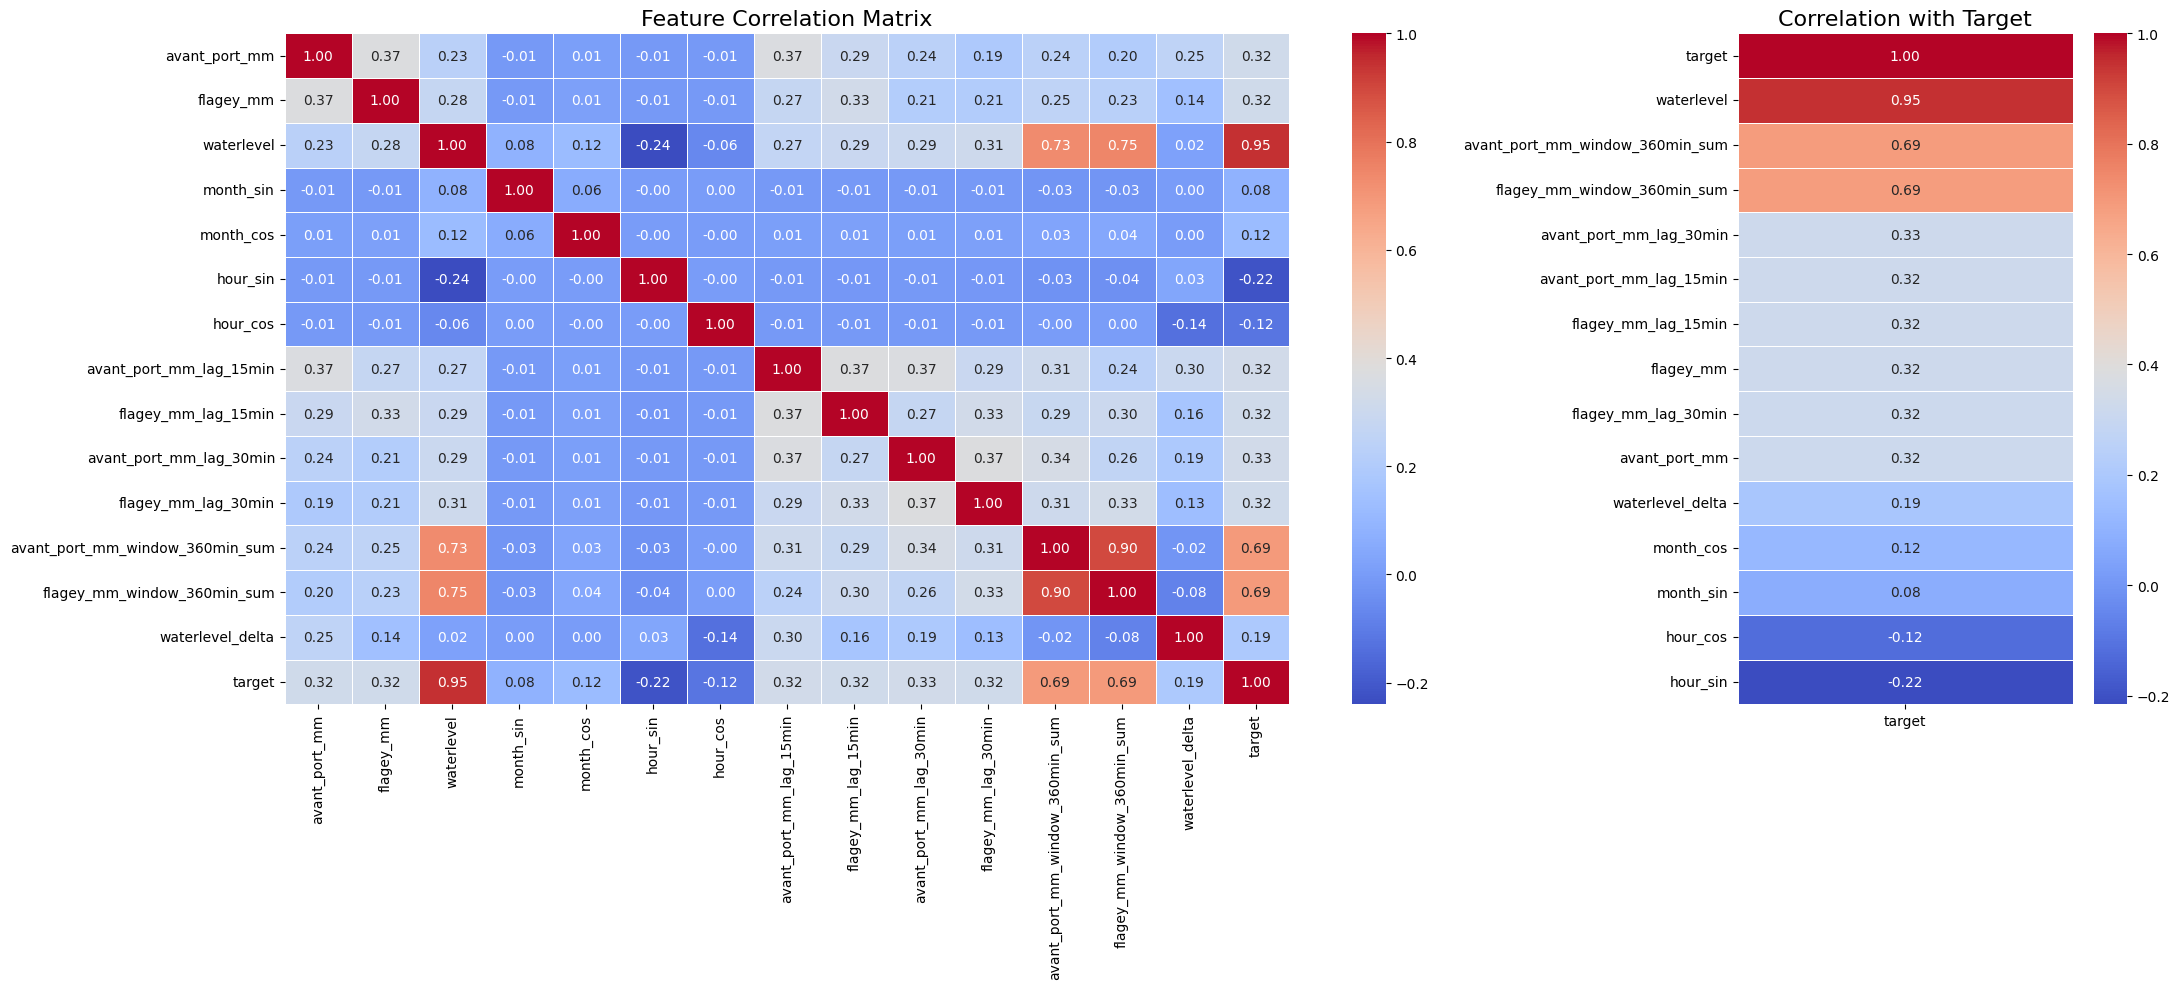

In [432]:
corr_matrix = X_train.join(y_train).corr()

correlations = corr_matrix['target'].abs().drop('target').sort_values(ascending=False)
top_features = correlations.head(10).index.tolist()


fig, ax = plt.subplots(
    1, 2,
    figsize=(22, 10),
    gridspec_kw={'width_ratios': [3, 1]}
)

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    ax=ax[0]
)

ax[0].set_title("Feature Correlation Matrix", fontsize=16)

sns.heatmap(
    corr_matrix[['target']].sort_values(by='target', ascending=False),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    ax=ax[1]
)

ax[1].set_title("Correlation with Target", fontsize=16)

plt.tight_layout()
plt.show()

It should be noted that the importance of the cyclical features cannot be correctly identified with a correlation matrix. Nevertheless, an approximation can be done by summing the importances of the sin and cos features. That would leave us with:
- hour = 0.34
- month = 0.20

Taking this into account, hour will rank on place 5 and the combination of hour_cos and hour_sin should therefore be included in the models. Since hour_sin is already in the top 10, we will only add hour_cos to be complete.

In [433]:
top_features.append('hour_cos')
top_features

['waterlevel',
 'avant_port_mm_window_360min_sum',
 'flagey_mm_window_360min_sum',
 'avant_port_mm_lag_30min',
 'avant_port_mm_lag_15min',
 'flagey_mm_lag_15min',
 'flagey_mm',
 'flagey_mm_lag_30min',
 'avant_port_mm',
 'hour_sin',
 'hour_cos']

The top 10 ranked features were selected and used consistently across the train-validation, training, validation, and test sets.

In [434]:
X_train_val = df_train_val[top_features]
X_train = df_train[top_features]
X_val = df_val[top_features]
X_test = df_test[top_features]

|We do the same for the 15 minutes as well.

In [435]:

X_train_val_15min = df_train_val_15min[top_features]
X_train_15min = df_train_15min[top_features]
X_val_15min = df_val_15min[top_features]
X_test_15min = df_test_15min[top_features]

## Helper Functions

Defining helper functions for model evaluation.

Computing **MSE**, **RMSE**, **MAE**, **R2**, and **NSE** to evaluate regression-based models.

The **NSE** measures how well a model's predictions align with the true value, using the average of the true values.
It is a widely used statistical metric with hydrological models (we will use it for our model selection).

**NSE = 1:** Perfect predictive match.

**NSE = 0:** The model's predictive ability is exactly the same as just predicting the average of the observed data.

**NSE < 0:** The model performs worse than simply using the historical average of the observed data.

In [436]:
def compute_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    nse = 1 - (np.sum((y_true - y_pred)**2) / np.sum((y_true - np.mean(y_true))**2))
    return {
        "mse": mse,
        "rmse": np.sqrt(mse),
        "mae": mae,
        "r2": r2,
        "nse": nse
    }

Intuition for each plot

1. **Actual vs Predicted:** Checks how closely the model’s predictions match the real values.
- Points close to the red diagonal line → accurate predictions
- Large spread away from the line → large prediction errors or weak model fit

2. **Residuals Over Time:** Shows how prediction errors behave across the sequence of data points.
- Random scatter around 0 → model is capturing the signal well
- Large spikes away from 0 → the model makes occasional big errors

3. **Q-Q Plot:** Compares the distribution of predicted values vs actual values.
- Points close to the diagonal → predicted distribution matches real distribution well
- Curving or systematic deviation → model is failing to capture extremes (too small or too large values)

4. **Residual Distribution:** Shows how errors are distributed overall.
- Centered around 0 → predictions are unbiased on average
- Wide spread → model is noisy or unstable
- Skewed distribution → systematic overprediction or underprediction (bias)

In [437]:
def plot_prediction(y_true, y_pred):
    y_pred = pd.Series(y_pred, index=y_true.index) if isinstance(y_pred, np.ndarray) else y_pred
    r = y_true - y_pred

    fig, ax = plt.subplots(2, 2, figsize=(16, 7))

    # Actual vs Predicted
    mn, mx = min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())
    ax[0,0].scatter(y_true, y_pred, s=5, alpha=0.3)
    ax[0,0].plot([mn, mx], [mn, mx], 'r--')
    ax[0,0].set(title="Actual vs Predicted", xlabel="Actual", ylabel="Predicted")

    # Residuals over samples
    ax[0,1].plot(r, lw=0.7, alpha=0.8)
    ax[0,1].axhline(0, color='r', ls='--')
    ax[0,1].set(title="Residuals", xlabel="Sample", ylabel="Error")

    # Q-Q plot
    q = np.linspace(0, 100, 100)
    qt, qp = np.percentile(y_true, q), np.percentile(y_pred, q)
    ax[1,0].plot(qt, qp, 'o', ms=3, alpha=0.6)
    ax[1,0].plot([qt.min(), qt.max()], [qt.min(), qt.max()], 'r--')
    ax[1,0].set(title="Q-Q Plot", xlabel="Observed quantiles", ylabel="Predicted quantiles")

    # Residual distribution
    ax[1,1].hist(r, bins=50, edgecolor='black', alpha=0.7)
    ax[1,1].axvline(0, color='r', ls='--')
    ax[1,1].set(title="Residual Distribution", xlabel="Residual")

    for a in ax.flat:
        a.grid(True)

    plt.tight_layout()
    plt.show()

## Baseline

The persistence baseline is a simple naive forecasting method.
Since the target `y_val` represents the water level one hour after the current row, we use the current water level `X_val['waterlevel']` as the prediction. Therefore, the model assumes that the water level at time \(n+1\) will be equal to the water level at time \(n\).

In [438]:
y_pred_bl = X_val['waterlevel']

This sets a performance floor — any trained model should beat this.

In [439]:
y_pred_bl = X_val['waterlevel']
bl_metrics = compute_metrics(y_val, y_pred_bl)
# plot_prediction(y_val, y_pred_bl)
print(bl_metrics)

print(f"""
The baseline simply predicts that the water level in 60 minutes will be the same as it is now.
RMSE: {bl_metrics['rmse']:.1f}mm | NSE: {bl_metrics['nse']:.3f}
This is the floor — every trained model should score higher than this.
""")

{'mse': 28851.282421542033, 'rmse': np.float64(169.85665256781093), 'mae': 102.59303725042693, 'r2': 0.9180780584632232, 'nse': np.float64(0.9180780584632232)}

The baseline simply predicts that the water level in 60 minutes will be the same as it is now.
RMSE: 169.9mm | NSE: 0.918
This is the floor — every trained model should score higher than this.



## ANN

Weights & Biases is used to track the experiments. During training, it records important information such as the hyperparameters, training loss, validation loss, and evaluation metrics.

This is useful because the model is trained multiple times with different settings. Instead of manually saving the results for each run, Weights & Biases keeps everything in one place and makes it easier to compare experiments.

It also provides visual plots of the training process.

In [440]:
os.environ["WANDB_SILENT"] = "true"

Suppress W&B console output to keep notebook logs clean.

Register the sweep with W&B; returns a sweep_id used to launch agents.

In [441]:
wandb.login("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")

True

**Hyperparameter**

This config tells Weights & Biases what to try and how to try it.

**Search method - Bayesian optimisation:**
Instead of trying random combinations blindly, Bayesian optimisation learns from each trial. After a few runs it starts suggesting settings that are more likely to improve the result. This saves time when each trial is expensive to run.

**What each setting controls:**

- `hidden_layer_sizes`: The shape of the network. A single `(64,)` layer is simple and fast. A deeper `(64, 32, 16)` network can learn more complex patterns but may overfit on small data.

- `learning_rate_init`: How big a step the model takes when updating its weights. Too small and it learns too slowly. Too large and it overshoots and never converges. We search on a log scale because the right value could be `0.0001` or `0.01`.

- `batch_size`: How many data points are used per update step. Small batches are noisier but can help generalisation. Large batches are more stable.

- `activation`: `relu` is the standard choice and works well in most cases. `tanh` is an alternative that sometimes does better when outputs can be negative.

- `alpha`: Controls how much the model is penalised for having large weights (preventing overfitting). Higher values reduce overfitting but can make the model too simple.

- `solver`: `adam` is the default and adjusts the learning rate automatically. `sgd` is simpler but needs more manual tuning.

The metric being maximised is the average R² across the time-series cross-validation folds. A higher R² means the model estimates better.

In [442]:
sweep_config = {
    "method": "bayes",
    "metric": {
        "name": "cv/accuracy_mean",
        "goal": "maximize"
    },
    "parameters": {
        "hidden_layer_sizes": {
            # Covers shallow-to-deep architectures
            "values": [
                (32,),
                (64,),
                (128,),
                (64, 32),
                (128, 64),
                (64, 32, 16)
            ]
        },
        "learning_rate_init": {
            "distribution": "log_uniform_values",
            "min": 1e-4,  # Below this, convergence is too slow for max_iter=200
            "max": 1e-2   # Above this, training tends to overshoot and diverge
        },
        "batch_size": {
            "values": [32, 64, 128, 256]
        },
        "activation": {
            "values": ["relu", "tanh"]
        },
        "alpha": {
            # L2 regularisation strength; log scale for the same reason as learning rate
            "distribution": "log_uniform_values",
            "min": 1e-5,
            "max": 1e-2
        },
        "solver": {
            "values": ["adam", "sgd"]
        },

        # Fixed Parameters
        "early_stopping":       {"value": True},   # Halts training when val loss stops improving
        "validation_fraction":  {"value": 0.1},    # 10% of training data held out for early stopping
        "max_iter":             {"value": 200},    # Sufficient for adam with early stopping
        "n_iter_no_change":     {"value": 10}      # 10 epochs of no improvement before stopping
    }
}

Register the hyperparameter sweep, and project information.

In [443]:
entity = "sinakhaji5-vrije-universiteit-brussel"
project = "ann-cv"
sweep_id = wandb.sweep(sweep_config, project=project)

Create sweep with ID: amftgx10
Sweep URL: https://wandb.ai/sinakhaji5-vrije-universiteit-brussel/ann-cv/sweeps/amftgx10


**ANN Pipeline – Target Scaling**

The original pipeline only scaled `X`, leaving `y` unscaled and causing poor convergence (and taking very long). Wrapping the regressor with `TransformedTargetRegressor` fixes this — it scales `y` internally during `fit` and inverse transforms predictions back to the original scale during `predict`.

```python
("ann", MLPRegressor(**cfg))
```

```python
("ann", TransformedTargetRegressor(
    regressor=MLPRegressor(**cfg),
    transformer=StandardScaler()
))
```

In [444]:
def sweep_train_cv(project, X_train, y_train, random_state, n_splits):
    with wandb.init(project=project) as run:
        cfg = dict(run.config)

        model = Pipeline([
            # Removes the mean and scales each feature to unit variance so that features on larger scales don't dominate the coefficients.
            ("scaler", StandardScaler()),
                ("ann", TransformedTargetRegressor(
                    regressor=MLPRegressor(**cfg),
                    transformer=StandardScaler()
                ))
        ])

        # TimeSeriesSplit is used so that the model always trains on the past and validates on the future.
        # Averaging R² across multiple folds gives a more reliable performance estimate than a single split.
        cv = TimeSeriesSplit(n_splits=n_splits)
        scores = cross_val_score(
            model, X_train, y_train,
            cv=cv, scoring="r2", n_jobs=-1 # use all available cores
        )

        # cv/accuracy_mean (the average R² from TimeSeriesSplit) is the metric W&B uses to rank sweep runs.
        run.log({
            "cv/accuracy_mean": float(scores.mean())
        })

Start the training (count is the number of times we train with new hyperparameters).

In [445]:
wandb.agent(
    sweep_id,
    function=lambda: sweep_train_cv(
        project=project,
        X_train=X_train,
        y_train=y_train,
        random_state=random_state,
        n_splits=3 # this config is a good balance between accuracy and computational cost based on experience
    ),
    count=4
)

 Create and fit the modelRetrain on the full training set using the best hyperparameters found by the sweep.
The validation fold used during the sweep is included in training.

In [446]:
def retrain_best_and_test(entity, project, sweep_id, X_train, y_train):
    api = wandb.Api()
    sweep = api.sweep(f"{entity}/{project}/{sweep_id}")

    # Fetch the run with the highest cv/accuracy_mean from the sweep
    best = sweep.best_run(order="cv/accuracy_mean").load_full_data()

    raw_cfg = dict(best["rawconfig"])

    # W&B stores all config keys including internal ones, so we filter
    # to only the parameters MLPRegressor actually accepts
    valid_params = MLPRegressor().get_params().keys()
    cfg = {k: v for k, v in raw_cfg.items() if k in valid_params}

    pipe = Pipeline([
         ("scaler", StandardScaler()),
            ("ann", TransformedTargetRegressor(
                regressor=MLPRegressor(**cfg),
                transformer=StandardScaler()
            ))
    ])

    pipe.fit(X_train, y_train)

    return pipe, cfg

In [447]:
ann_pipe, best_hparams = retrain_best_and_test(
    entity=entity,
    project=project,
    sweep_id=sweep_id,
    X_train=X_train,
    y_train=y_train
)

Best hyperparameters found by the sweep:

In [448]:
pprint.pprint(best_hparams)

{'activation': 'tanh',
 'alpha': 0.00037620550209452504,
 'batch_size': 128,
 'early_stopping': True,
 'hidden_layer_sizes': [64],
 'learning_rate_init': 0.0005343258997965396,
 'max_iter': 200,
 'n_iter_no_change': 10,
 'solver': 'adam',
 'validation_fraction': 0.1}


In [449]:
y_pred_ann = ann_pipe.predict(X_val)
ann_val_metrics = compute_metrics(y_val, y_pred_ann)
# plot_prediction(y_val, y_pred_ann)
print(ann_val_metrics)

print(f"""
The ANN predicted water levels 60 minutes ahead.
RMSE: {ann_val_metrics['rmse']:.1f}mm | MAE: {ann_val_metrics['mae']:.1f}mm | NSE: {ann_val_metrics['nse']:.3f}
Predictions are on average off by {ann_val_metrics['mae']/10:.1f}cm.
""")

{'mse': 17682.24215472174, 'rmse': np.float64(132.97459213970816), 'mae': 73.55494698061659, 'r2': 0.9497920547560595, 'nse': np.float64(0.9497920547560595)}

The ANN predicted water levels 60 minutes ahead.
RMSE: 133.0mm | MAE: 73.6mm | NSE: 0.950
Predictions are on average off by 7.4cm.



## Random Forest Regressor
Here we will train on the training set, but use RandomizedSearchCV with internal cross-validation.

This code performs a small random hyperparameter sweep for the Random Forest model. It searches over the number of trees, maximum tree depth, minimum samples required to split a node, and minimum samples per leaf. `RandomizedSearchCV` tests randomly selected configurations and evaluates them using 'cv'-fold cross-validation with R² as the scoring metric.

In [450]:
rf_pipe = Pipeline([
    #scaling is not needed in RandomForests (https://kundan-reads.readthedocs.io/en/latest/aiml/machine_learning/random_forest_regressor/)
    ('regressor', RandomForestRegressor(random_state=random_state))
])

param_dist_rf = {
    'regressor__n_estimators':    randint(50, 200),  # more trees = more stable predictions
    'regressor__max_depth':       [3, 5, 7, 10],     # limits tree depth to prevent overfitting
    'regressor__min_samples_split': randint(2, 11),  # minimum samples required to split a node
    'regressor__min_samples_leaf':  [1, 2, 4]        # minimum samples required at a leaf node
}

rf_random_search = RandomizedSearchCV(rf_pipe,
                                      param_distributions=param_dist_rf,
                                      n_iter=10,
                                      cv=TimeSeriesSplit(n_splits=3), # TimeSeriesSplit for the same reason as the ANN sweep, prevents future leakage
                                                                        # this config is a good balance between accuracy and computational cost based on experience
                                      scoring='r2',
                                      random_state=random_state,
                                      n_jobs=-1) # use all available cores
rf_random_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._state=138))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__max_depth': [3, 5, ...], 'regressor__min_samples_leaf': [1, 2, ...], 'regressor__min_samples_split': <scipy.stats....x7f0281fc9220>, 'regressor__n_estimators': <scipy.stats....x7f02819ad590>}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide

Best hyperparameters found by the sweep:

In [451]:
print(rf_random_search.best_params_)

{'regressor__max_depth': 7, 'regressor__min_samples_leaf': 4, 'regressor__min_samples_split': 4, 'regressor__n_estimators': 187}


In [452]:
rf_pipe = rf_random_search.best_estimator_
y_pred_rf = rf_pipe.predict(X_val)
rf_val_metrics = compute_metrics(y_val, y_pred_rf)
# plot_prediction(y_val, y_pred_rf)
print(rf_val_metrics)

print(f"""
The Random Forest predicted water levels 60 minutes ahead.
RMSE: {rf_val_metrics['rmse']:.1f}mm | MAE: {rf_val_metrics['mae']:.1f}mm | NSE: {rf_val_metrics['nse']:.3f}
Best hyperparameters: {rf_random_search.best_params_}
""")

{'mse': 20501.144757935894, 'rmse': np.float64(143.18220824507455), 'mae': 81.44404633470741, 'r2': 0.9417879053777306, 'nse': np.float64(0.9417879053777306)}

The Random Forest predicted water levels 60 minutes ahead.
RMSE: 143.2mm | MAE: 81.4mm | NSE: 0.942
Best hyperparameters: {'regressor__max_depth': 7, 'regressor__min_samples_leaf': 4, 'regressor__min_samples_split': 4, 'regressor__n_estimators': 187}



## Linear model

In [453]:
lr_pipe = Pipeline([
    # Removes the mean and scales each feature to unit variance so that features on larger scales don't dominate the coefficients.
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

lr_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None


In [454]:
y_pred_lr = lr_pipe.predict(X_val)
lr_val_metrics = compute_metrics(y_val, y_pred_lr)
# plot_prediction(y_val, y_pred_lr)
print(lr_val_metrics)

print(f"""
The linear model predicted water levels 60 minutes ahead.
RMSE: {lr_val_metrics['rmse']:.1f}mm | MAE: {lr_val_metrics['mae']:.1f}mm | NSE: {lr_val_metrics['nse']:.3f}
""")

{'mse': 22598.066559387233, 'rmse': np.float64(150.32653311836614), 'mae': 86.43383918699044, 'r2': 0.935833788582651, 'nse': np.float64(0.935833788582651)}

The linear model predicted water levels 60 minutes ahead.
RMSE: 150.3mm | MAE: 86.4mm | NSE: 0.936



## Comparison

Here we compare all four models to find the best performing model.

Baseline:



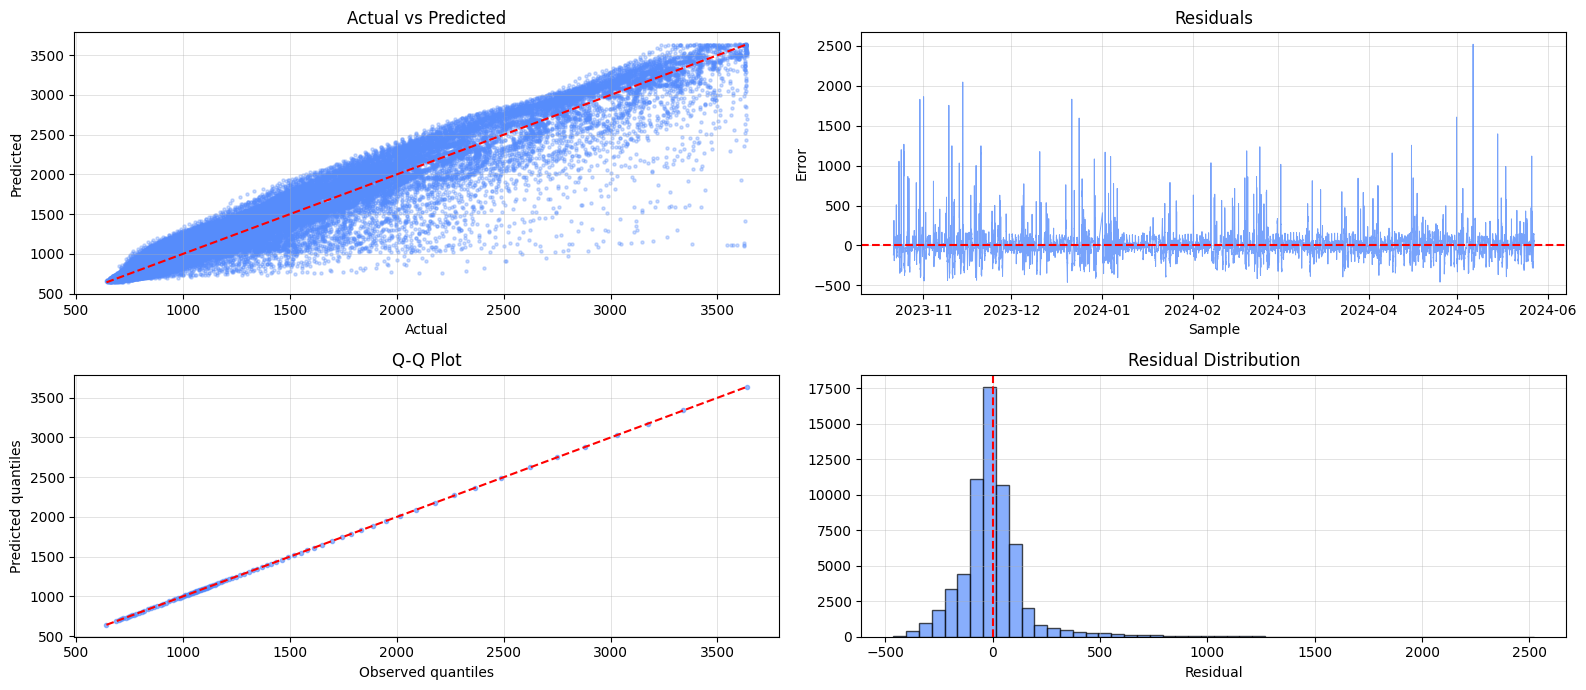

{'mse': 28851.282421542033, 'rmse': np.float64(169.85665256781093), 'mae': 102.59303725042693, 'r2': 0.9180780584632232, 'nse': np.float64(0.9180780584632232)}
Artificial Neural Network:



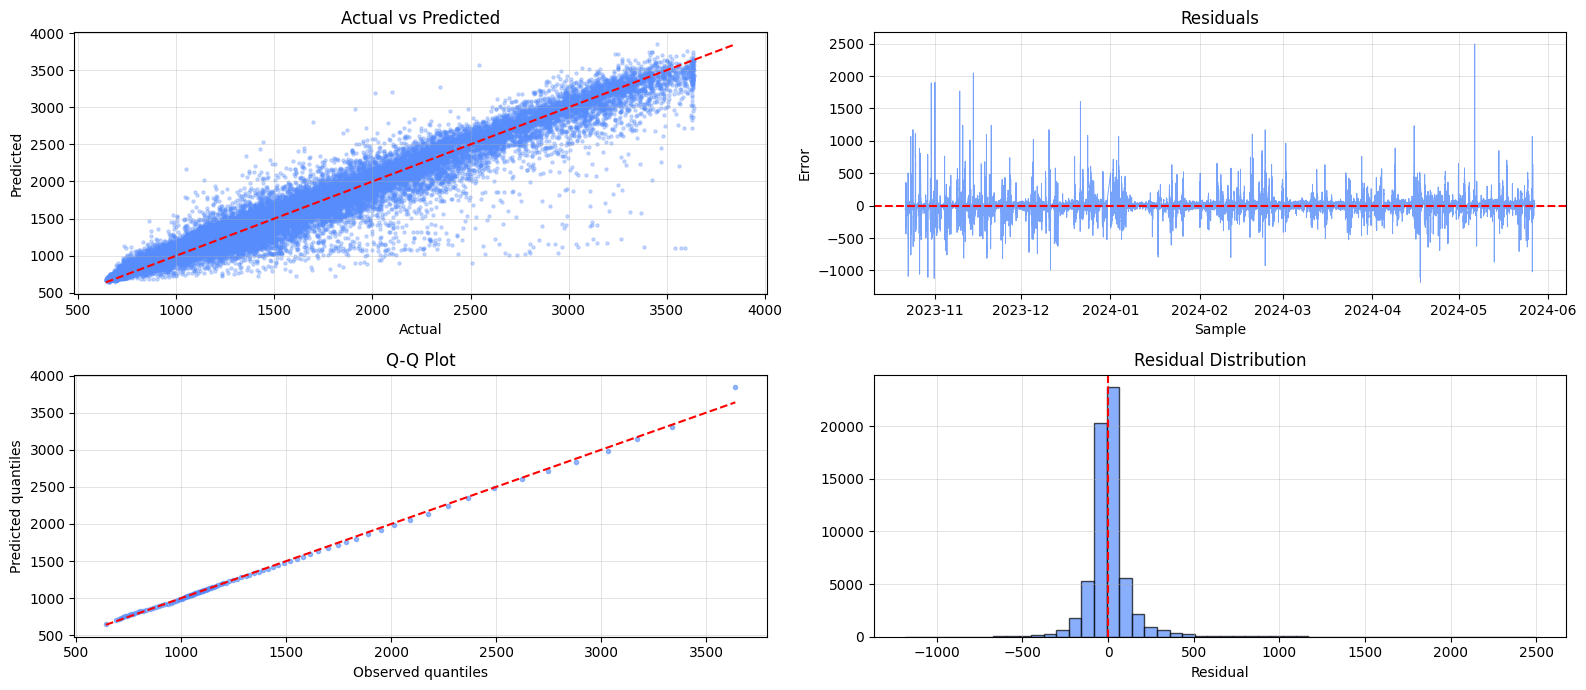

{'mse': 17682.24215472174, 'rmse': np.float64(132.97459213970816), 'mae': 73.55494698061659, 'r2': 0.9497920547560595, 'nse': np.float64(0.9497920547560595)}
Random Forest:



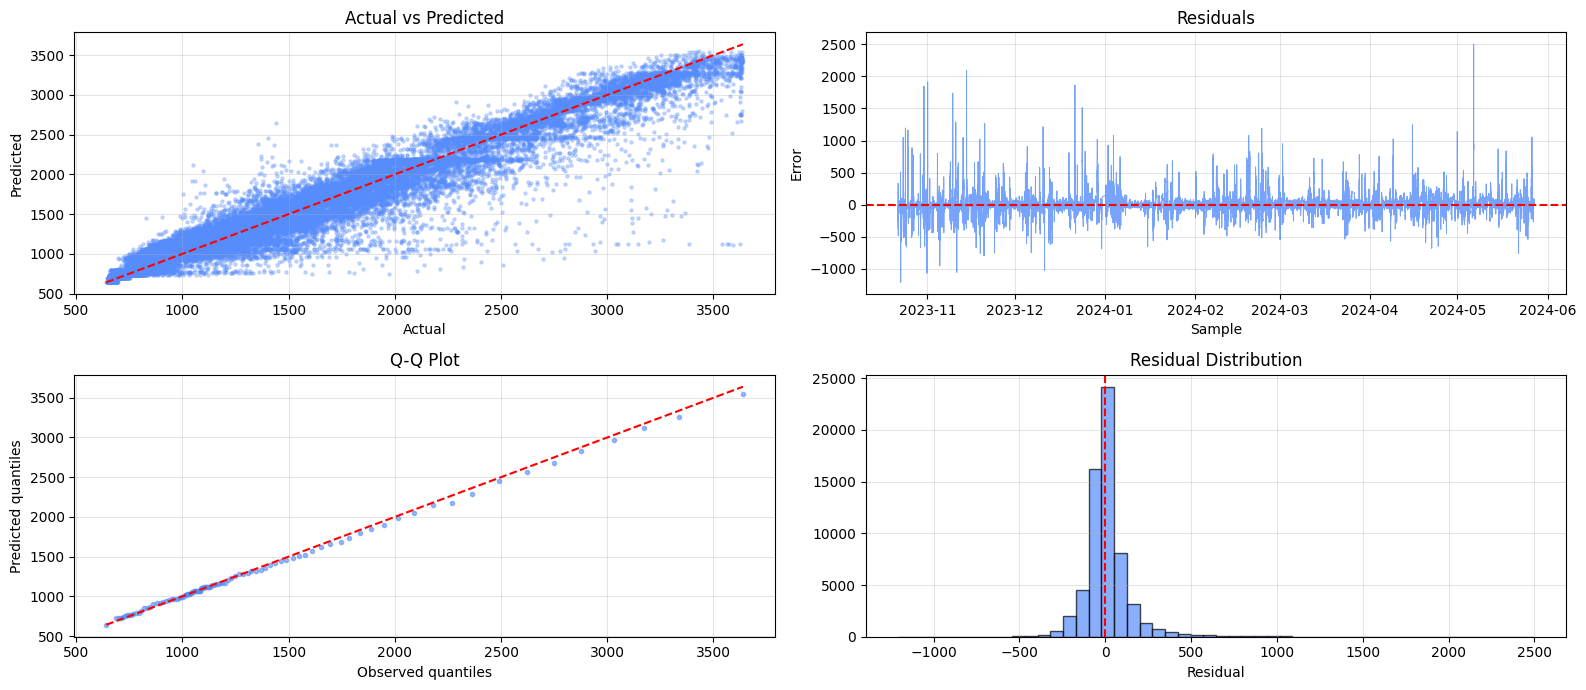

{'mse': 20501.144757935894, 'rmse': np.float64(143.18220824507455), 'mae': 81.44404633470741, 'r2': 0.9417879053777306, 'nse': np.float64(0.9417879053777306)}
Linear Regression:



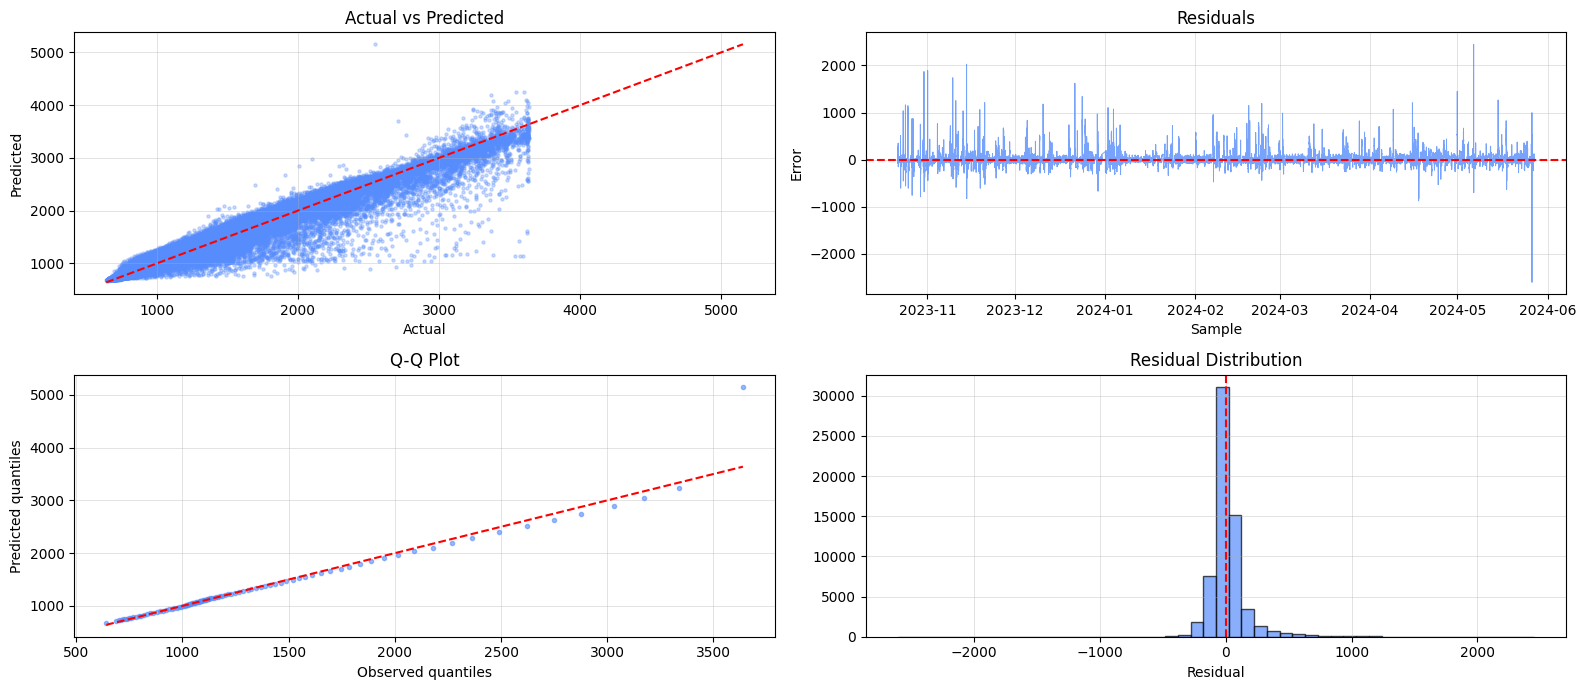

{'mse': 22598.066559387233, 'rmse': np.float64(150.32653311836614), 'mae': 86.43383918699044, 'r2': 0.935833788582651, 'nse': np.float64(0.935833788582651)}

--- Model Comparison (60-minute horizon) ---

                 RMSE      MAE       NSE
Baseline:        169.9mm   102.6mm   0.918
Linear:          150.3mm   86.4mm   0.936
Random Forest:   143.2mm   81.4mm   0.942
ANN:             133.0mm   73.6mm   0.950

All three trained models beat the baseline (NSE 0.918), confirming they have learned real patterns from the data.

The baseline already has a high NSE of 0.918, which makes sense water level changes slowly,
so predicting the current level as the future level is not a bad guess. However, it still carries an RMSE
of 169.9mm, meaning it can be off by around 17cm on average.

The linear model (NSE 0.936) improves over the baseline despite being the simplest trained model.
The gap between the linear model and the ANN is only 0.014 NSE points,
which suggests the original features alre

In [455]:
model_registry = {
    'lr_metrics':   lr_pipe,
    'rf_metrics':   rf_pipe,
    'ann_metrics':  ann_pipe,
    'bl_metrics':   None,
}

print('Baseline:\n')
bl_metrics = compute_metrics(y_val, y_pred_bl)
plot_prediction(y_val, y_pred_bl)
print(bl_metrics)

print('Artificial Neural Network:\n')
ann_val_metrics = compute_metrics(y_val, y_pred_ann)
plot_prediction(y_val, y_pred_ann)
print(ann_val_metrics)

print('Random Forest:\n')
rf_val_metrics = compute_metrics(y_val, y_pred_rf)
plot_prediction(y_val, y_pred_rf)
print(rf_val_metrics)

print('Linear Regression:\n')
lr_val_metrics = compute_metrics(y_val, y_pred_lr)
plot_prediction(y_val, y_pred_lr)
print(lr_val_metrics)

metrics = {'bl_metrics': bl_metrics, 'ann_metrics': ann_val_metrics, 'rf_metrics': rf_val_metrics, 'lr_metrics': lr_val_metrics}

best_name = max(metrics, key=lambda m: metrics[m]['nse'])
best_model = model_registry[best_name]

print(f"""
--- Model Comparison (60-minute horizon) ---

                 RMSE      MAE       NSE
Baseline:        {bl_metrics['rmse']:.1f}mm   {bl_metrics['mae']:.1f}mm   {bl_metrics['nse']:.3f}
Linear:          {lr_val_metrics['rmse']:.1f}mm   {lr_val_metrics['mae']:.1f}mm   {lr_val_metrics['nse']:.3f}
Random Forest:   {rf_val_metrics['rmse']:.1f}mm   {rf_val_metrics['mae']:.1f}mm   {rf_val_metrics['nse']:.3f}
ANN:             {ann_val_metrics['rmse']:.1f}mm   {ann_val_metrics['mae']:.1f}mm   {ann_val_metrics['nse']:.3f}

All three trained models beat the baseline (NSE {bl_metrics['nse']:.3f}), confirming they have learned real patterns from the data.

The baseline already has a high NSE of {bl_metrics['nse']:.3f}, which makes sense water level changes slowly,
so predicting the current level as the future level is not a bad guess. However, it still carries an RMSE
of {bl_metrics['rmse']:.1f}mm, meaning it can be off by around {bl_metrics['rmse']/10:.0f}cm on average.

The linear model (NSE {lr_val_metrics['nse']:.3f}) improves over the baseline despite being the simplest trained model.
The gap between the linear model and the ANN is only {ann_val_metrics['nse'] - lr_val_metrics['nse']:.3f} NSE points,
which suggests the original features already capturing most of the patterns.

The Random Forest (NSE {rf_val_metrics['nse']:.3f}) sits between the linear model and the ANN.
Its RMSE of {rf_val_metrics['rmse']:.1f}mm is {rf_val_metrics['rmse'] - ann_val_metrics['rmse']:.1f}mm higher than the ANN.

The ANN is the best model with NSE {ann_val_metrics['nse']:.3f} and RMSE {ann_val_metrics['rmse']:.1f}mm;
an improvement of {bl_metrics['rmse'] - ann_val_metrics['rmse']:.1f}mm over the baseline.
Given that the sweep only ran 4 trials, there is likely more performance to be gained with further tuning.
""")

**Visual Diagnostics**

**Baseline:** The scatter fans out heavily at higher values, and residuals are predominantly positive, showing the model lags behind rapid rises. The residual distribution has a long right tail to ~2500mm confirming this bias.

**ANN:** Tightest scatter of all four models. The residual distribution has the sharpest peak centered near zero but shows a right-skewed tail extending to ~2500mm. Q-Q plot tracks the reference line well up to ~2000mm with moderate deviation at the upper tail.

**Random Forest:** Wider scatter than the ANN with no visible banding. Residual spread is slightly broader than the ANN, with a notable negative spike around January 2024.

**Linear Regression:** the predicted axis extends to ~5500mm while actuals top out at ~3700mm, indicating over-prediction at extremes. The residual time series shows a negative drift in Feb–May 2024 that the other models do not show.

Looking at the validation scores, the ANN scores best, let's evaluate that one on the test set.

In [456]:
y_test_pred_ann = ann_pipe.predict(X_test)
ann_metrics = compute_metrics(y_test, y_test_pred_ann)
print(ann_metrics)
print(f'finalised accuracy: {ann_metrics['nse']}')

{'mse': 13469.290859899042, 'rmse': np.float64(116.05727404992348), 'mae': 51.35740196177818, 'r2': 0.9517124775162366, 'nse': np.float64(0.9517124775162366)}
finalised accuracy: 0.9517124775162366


Comparing the performance of our model on the validation and the test set, we get almost identical performance (0.95), which means that our model performs very well on unseen data and generalises well.


# Classification

Overflow is derived from the regression output by thresholding predicted water levels at 3000 mm; this is not a separate classification model.

In [457]:
def classify(series):
    df = series.to_frame()
    df['classification'] = np.where(df['target'] > 3000, 'overflow', 'not overflow')
    return df

Classify actual water levels using the same threshold.

In [458]:
df_test_class = classify(y_test)

Classify predicted water levels using the same threshold.

In [459]:
df_test_pred_class = classify(pd.Series(y_test_pred_ann, name='target'))

Extract the label columns for use in sklearn's metric functions.

In [460]:
y_test_class = df_test_class['classification']
y_test_pred_class = df_test_pred_class['classification']

The regression output is thresholded at 3000 mm to derive binary overflow labels.

**Confusion matrix**, shows exactly where the model makes mistakes:
- **True positive (TP):** correctly predicted overflow
- **True negative (TN):** correctly predicted not overflow
- **False positive (FP):** predicted overflow but was not
- **False negative (FN):** predicted not overflow but was

**Classification report**, per class breakdown:
- **Precision:** of all predicted overflows, how many were actual overflows
- **Recall:** of all actual overflows, how many did the model catch
- **F1:** harmonic mean of precision and recall, balances both
- **Support:** number of actual samples per class, directly reflects class imbalance

In [461]:
print("Confusion Matrix:\n", confusion_matrix(y_test_class, y_test_pred_class))
print("\nClassification Report:\n", classification_report(y_test_class, y_test_pred_class))

Confusion Matrix:
 [[60893   130]
 [  387  1248]]

Classification Report:
               precision    recall  f1-score   support

not overflow       0.99      1.00      1.00     61023
    overflow       0.91      0.76      0.83      1635

    accuracy                           0.99     62658
   macro avg       0.95      0.88      0.91     62658
weighted avg       0.99      0.99      0.99     62658



The model demonstrates excellent overall classification performance and is especially strong at identifying non-overflow conditions.
In addition, the high precision for the overflow class shows that predicted overflow events are highly reliable.
However, the recall value of 0.76 for overflow prediction indicates that some overflow events are still not detected.

In simpler terms, if the model predicts an overflow, there is a very high chance that an overflow will actually occur. However, there is still a possibility that the model may fail to detect some overflow events.

The dataset is heavily imbalanced. Only 2.6% of samples are overflow events, so overall accuracy is a misleading metric here. A model that always predicted "no overflow" would always be better at predicting "no overflow".

The model demonstrates excellent overall classification performance and is especially strong at identifying non-overflow conditions.

# Model Reevaluation (15 minutes)

## Training

Here we will re-evaluate the best model’s accuracy for (t + 15).

The best-performing model has consistently been the ANN/MLP model after numerous runs.

Note that the model has to be retrained, since it was originally trained on a dataset with a target value of 60-minute intervals. However, we are now trying to predict 15 minutes ahead; therefore, a new model needs to be trained.

The hyperparameters were also re-evaluated, as we assumed that the ANN model’s performance might improve further if trained with more appropriate hyperparameter values for this shorter prediction horizon.

In [462]:
project = "ann-cv-15min"
sweep_id = wandb.sweep(sweep_config, project=project)

Create sweep with ID: 34g8s4hk
Sweep URL: https://wandb.ai/sinakhaji5-vrije-universiteit-brussel/ann-cv-15min/sweeps/34g8s4hk


Start the training (count is the number of times we train with new hyperparameters).

In [463]:
wandb.agent(
    sweep_id,
    function=lambda: sweep_train_cv(
        project=project,
        X_train=X_train_15min,
        y_train=y_train_15min,
        random_state=random_state,
        n_splits=3 # this config is a good balance between accuracy and computational cost based on experience
    ),
    count=4
)

Retrain on the full training set using the best hyperparameters found by the sweep.
The validation fold used during the sweep is included in training.

In [464]:
ann_pipe, best_hparams = retrain_best_and_test(
    entity=entity,
    project=project,
    sweep_id=sweep_id,
    X_train=X_train_15min,
    y_train=y_train_15min
)

Best hyperparameters found by the sweep:

In [465]:
pprint.pprint(best_hparams)

{'activation': 'relu',
 'alpha': 0.004484292441768535,
 'batch_size': 64,
 'early_stopping': True,
 'hidden_layer_sizes': [128, 64],
 'learning_rate_init': 0.00032241708046139707,
 'max_iter': 200,
 'n_iter_no_change': 10,
 'solver': 'adam',
 'validation_fraction': 0.1}


## Evaluation

We evaluate the key metric of our newly trained model. However, since we are comparing it against the 60-minute model, we evaluate it on the test set because we are not choosing between models, but only comparing their fixed accuracy, as both models are designed for different purposes.

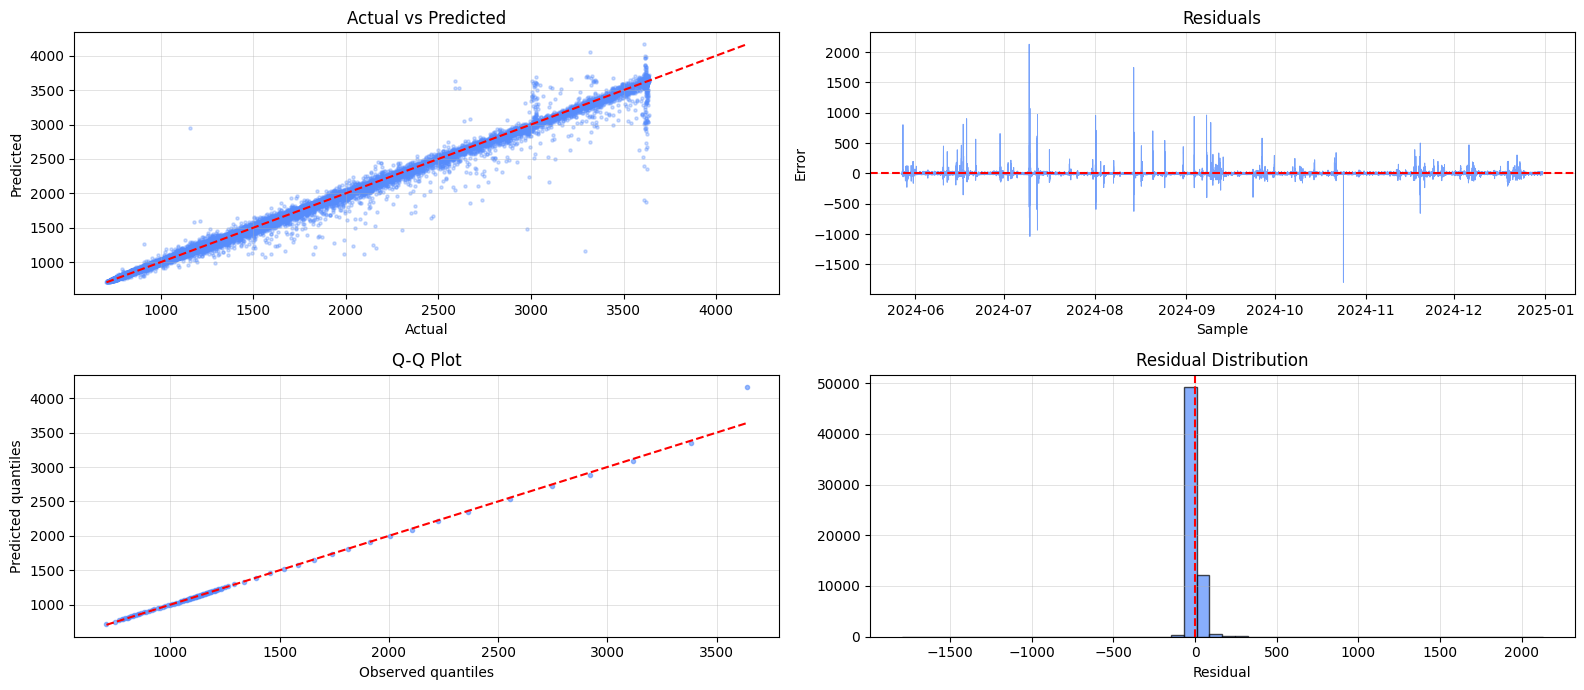

{'mse': 1846.2609456480743, 'rmse': np.float64(42.96813872682961), 'mae': 16.373305520765584, 'r2': 0.99338041903515, 'nse': np.float64(0.99338041903515)}

Final test results for the 15-minute model on unseen data.
RMSE: 43.0mm | MAE: 16.4mm | NSE: 0.993

The 15-minute model improves over the 60-minute model (NSE 0.952 → 0.993, RMSE 116.1mm → 43.0mm).

Both models are still very for different purposes: a 15-minute warning allows operators to react immediately,
while a 60-minute warning gives time to plan ahead.



In [466]:
y_15min_pred_ann = ann_pipe.predict(X_test_15min)
ann_15min_metrics = compute_metrics(y_test_15min, y_15min_pred_ann)
plot_prediction(y_test_15min, y_15min_pred_ann)
print(ann_15min_metrics)

print(f"""
Final test results for the 15-minute model on unseen data.
RMSE: {ann_15min_metrics['rmse']:.1f}mm | MAE: {ann_15min_metrics['mae']:.1f}mm | NSE: {ann_15min_metrics['nse']:.3f}

The 15-minute model {'improves' if ann_15min_metrics['nse'] - ann_metrics['nse'] > 0.02 else 'does not improve'} over the 60-minute model (NSE {ann_metrics['nse']:.3f} → {ann_15min_metrics['nse']:.3f}, RMSE {ann_metrics['rmse']:.1f}mm → {ann_15min_metrics['rmse']:.1f}mm).

Both models are still very for different purposes: a 15-minute warning allows operators to react immediately,
while a 60-minute warning gives time to plan ahead.
""")

Given these metrics, we can conclude that the 15 minute model is much better at predicting the waterlevel of sewage than predicting at t+60. The R2 and NSE are both now at 0.99, which is an incredible performance. Although in the EDA, we saw some intense spikes that can happen within 5 minutes, most waterlevel changes are gradual or at least slower than that. The fact that t+15 performs better than t+60 indicates that the sewer responds to changes rather fast (15 minutes is a good prediction time). The fact that the current waterlevel was the most important feature could also indicate that current waterlevel alone is a better predictor of waterlevel in 15 minutes than in 1 hour. However, we cannot say with certainty which feature leads to the better performance in the shorter term.

## Classification

We used the classify() function to classify our prediction and evaluate them as well.

Classify actual water levels using the same threshold.

In [467]:
df_test_class = classify(y_test_15min)

Classify predicted water levels using the same threshold.

In [468]:
df_test_pred_class = classify(pd.Series(y_15min_pred_ann, name='target'))

Extract the label columns for use in sklearn's metric functions.

In [469]:
y_test_class = df_test_class['classification']
y_test_pred_class = df_test_pred_class['classification']

The regression output is thresholded at 3000 mm to derive binary overflow labels.

**Confusion matrix**, shows exactly where the model makes mistakes:
- **True positive (TP):** correctly predicted overflow
- **True negative (TN):** correctly predicted not overflow
- **False positive (FP):** predicted overflow but was not
- **False negative (FN):** predicted not overflow but was

**Classification report**, per class breakdown:
- **Precision:** of all predicted overflows, how many were actual overflows
- **Recall:** of all actual overflows, how many did the model catch
- **F1:** harmonic mean of precision and recall, balances both
- **Support:** number of actual samples per class, directly reflects class imbalance

In [470]:
print("Confusion Matrix:\n", confusion_matrix(y_test_class, y_test_pred_class))
print("\nClassification Report:\n", classification_report(y_test_class, y_test_pred_class))

Confusion Matrix:
 [[61013    17]
 [  110  1525]]

Classification Report:
               precision    recall  f1-score   support

not overflow       1.00      1.00      1.00     61030
    overflow       0.99      0.93      0.96      1635

    accuracy                           1.00     62665
   macro avg       0.99      0.97      0.98     62665
weighted avg       1.00      1.00      1.00     62665



Compared to the previous model, the overflow recall improves significantly from 0.76 to 0.96, meaning the model is now much better at correctly identifying actual overflow events and **misses far fewer of them**.

The F1-score also increases from 0.83 to 0.97, showing a much better balance between precision and recall.

In simple terms, compared to the earlier model, this version is much stronger at catching overflow events, and probably because we have smaller interval and the data at those interval is more similar to what we already have.

The dataset is heavily imbalanced. Only 2.6% of samples are overflow events, so overall accuracy is a misleading metric here. A model that always predicted "no overflow" would always be better at predicting "no overflow".

The model demonstrates even better overall classification.

**Note:** For the classification part, we used the test set simply because we had already chosen our models. The 60min and 15min models are not being tested to be compared and selected, but rather evaluated on the test set to confirm and lock in their accuracy, considering that both models are designed for different purposes and therefore cannot be directly compared.

In [471]:
print(f"60-min overflow count: {(y_test > 3000).sum()} out of {len(y_test)} - percent: {((y_test > 3000).sum() / len(y_test)) * 100:.4f}%")
print(f"15-min overflow count: {(y_test_15min > 3000).sum()} out of {len(y_test_15min)} - percent: {((y_test_15min > 3000).sum() / len(y_test_15min)) * 100:.4f}%")

60-min overflow count: 1635 out of 62658 - percent: 2.6094%
15-min overflow count: 1635 out of 62665 - percent: 2.6091%


Both test sets contain exactly 1635 overflow events (2.61%) because they cover the same time window and overflow is determined by the same underlying waterlevel series. The tiny difference in total size (62663 vs 62670) comes from the different shift lengths dropping a few extra rows.

**Disclaimer**: GenAI was used to restructure and improve the content of this notebook.

# References

Barani Design. (2020, January 19). Rain rate intensity classification. Retrieved May 22, 2026, from https://www.baranidesign.com/faq-articles/2020/1/19/rain-rate-intensity-classification

Shakil, A., Khalighi, M. A., Pudlo, P., Leclerc, C., Laplace, D., Hamon, F., & Boudonne, A. (2023). Outlier detection in non-stationary time series applied to sewer network monitoring. Internet of Things, 21, 100654.

Statista. (2025). Annual rainfall in Belgium from 2006 to 2016. Retrieved May 21, 2026, from https://www.statista.com/statistics/526023/annual-rainfall-in-belgium/?srsltid=AfmBOopepXmr7FuZuEtP6fQsaguOv97US-Dl1YOS84d2z1cvjOb9Q6bH
